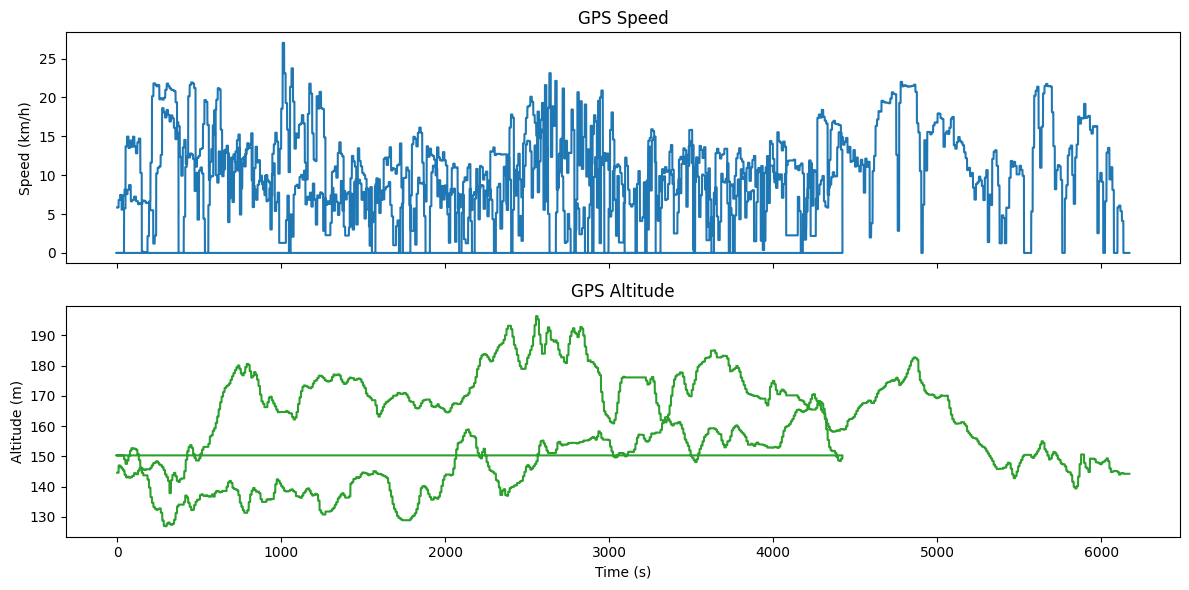

In [12]:
"""
Plot sensor data from S-M.csv (GPS + accelerometer + gyroscope + magnetometer + orientation).

Usage:
    pip install pandas matplotlib
    python plot_data.py S-M.csv
"""

import pandas as pd
import matplotlib.pyplot as plt

# ---- Load data ------------------------------------------------------------
# Set this to the path of your CSV file (edit as needed).
csv_path = "S-M.csv"
df = pd.read_csv(csv_path)

# Clean up column names (strip leading/trailing spaces)
df.columns = [c.strip() for c in df.columns]

# Time axis in seconds, starting from 0
df["TIME (s)"] = (df["TIME SINCE START (ms)"] - df["TIME SINCE START (ms)"].iloc[0]) / 1000.0

# ---- Figure 1: GPS speed & altitude ---------------------------------------
fig1, axes1 = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes1[0].plot(df["TIME (s)"], df["GPS SPEED (Kmh)"], color="tab:blue")
axes1[0].set_ylabel("Speed (km/h)")
axes1[0].set_title("GPS Speed")

axes1[1].plot(df["TIME (s)"], df["GPS ALTITUDE (m)"], color="tab:green")
axes1[1].set_ylabel("Altitude (m)")
axes1[1].set_xlabel("Time (s)")
axes1[1].set_title("GPS Altitude")

fig1.tight_layout()



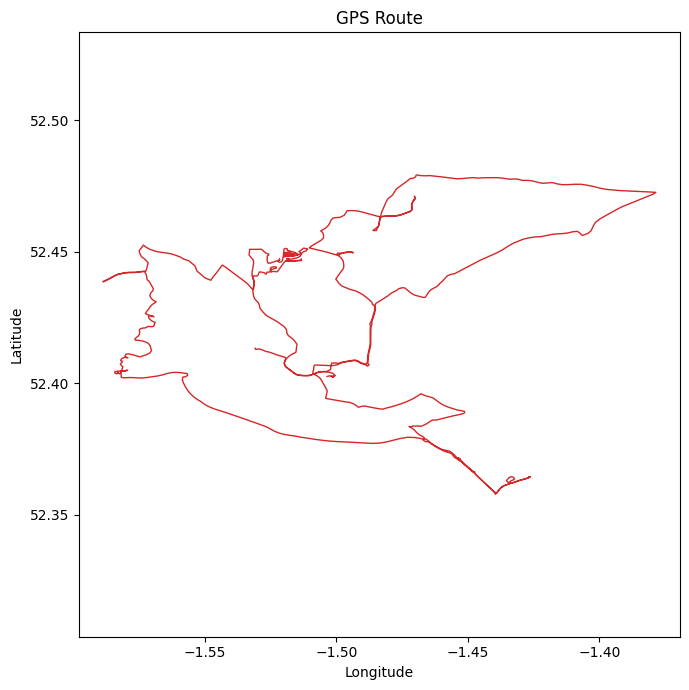

In [13]:
# ---- Figure 2: GPS route (lat vs lon) --------------------------------------
fig2, ax2 = plt.subplots(figsize=(7, 7))
ax2.plot(df["GPS LONGITUDE (degrees)"], df["GPS LATITUDE (degrees)"],
          color="tab:red", linewidth=1)
ax2.set_xlabel("Longitude")
ax2.set_ylabel("Latitude")
ax2.set_title("GPS Route")
ax2.set_aspect("equal", adjustable="datalim")
fig2.tight_layout()

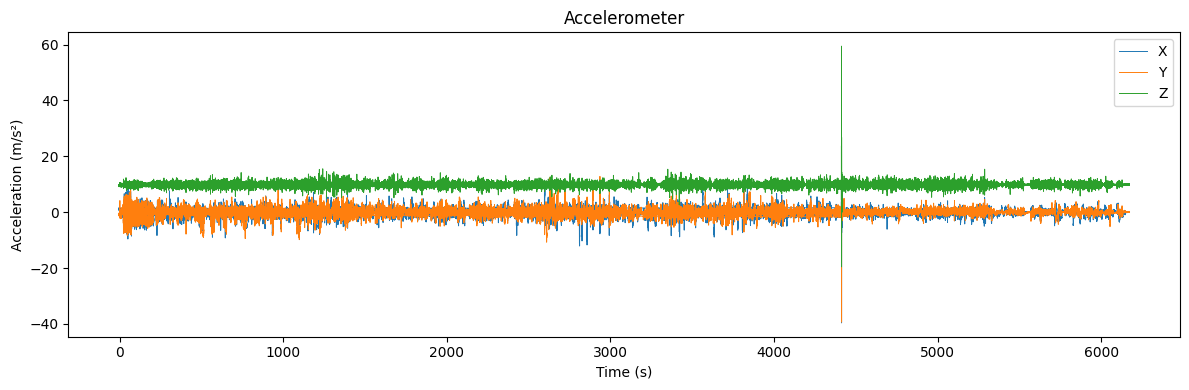

In [14]:
# ---- Figure 3: Accelerometer XYZ ------------------------------------------
fig3, ax3 = plt.subplots(figsize=(12, 4))
ax3.plot(df["TIME (s)"], df["ACCELEROMETER X (m/s)"], label="X", linewidth=0.7)
ax3.plot(df["TIME (s)"], df["ACCELEROMETER Y (m/s)"], label="Y", linewidth=0.7)
ax3.plot(df["TIME (s)"], df["ACCELEROMETER Z (m/s)"], label="Z", linewidth=0.7)
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Acceleration (m/s²)")
ax3.set_title("Accelerometer")
ax3.legend()
fig3.tight_layout()

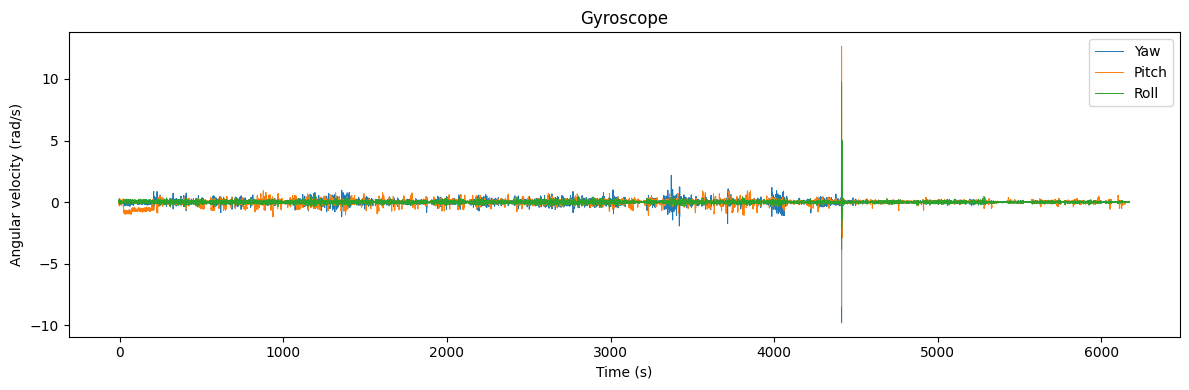

In [15]:
# ---- Figure 4: Gyroscope Yaw/Pitch/Roll ------------------------------------
fig4, ax4 = plt.subplots(figsize=(12, 4))
ax4.plot(df["TIME (s)"], df["GYROSCOPE Yaw (rad/s)"], label="Yaw", linewidth=0.7)
ax4.plot(df["TIME (s)"], df["GYROSCOPE Pitch (rad/s)"], label="Pitch", linewidth=0.7)
ax4.plot(df["TIME (s)"], df["GYROSCOPE Roll (rad/s)"], label="Roll", linewidth=0.7)
ax4.set_xlabel("Time (s)")
ax4.set_ylabel("Angular velocity (rad/s)")
ax4.set_title("Gyroscope")
ax4.legend()
fig4.tight_layout()

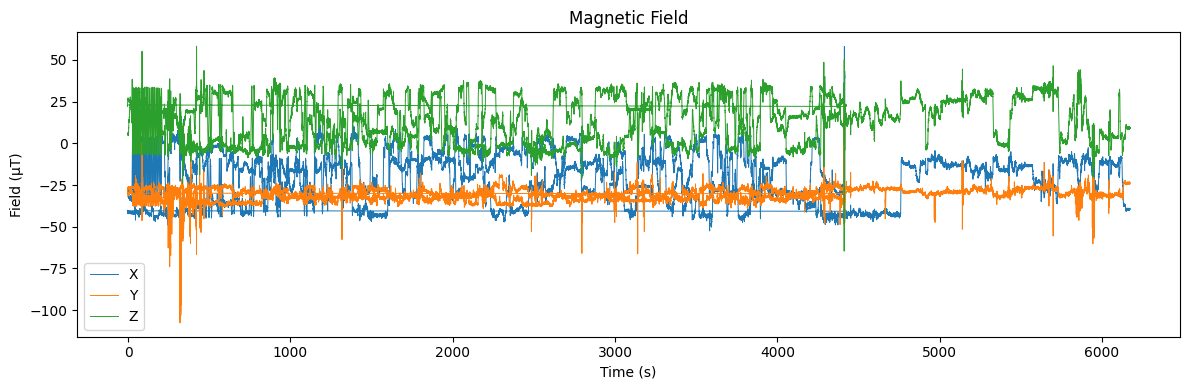

In [16]:
# ---- Figure 5: Magnetic field XYZ ------------------------------------------
fig5, ax5 = plt.subplots(figsize=(12, 4))
ax5.plot(df["TIME (s)"], df["MAGNETIC FIELD X (μT)"], label="X", linewidth=0.7)
ax5.plot(df["TIME (s)"], df["MAGNETIC FIELD Y (μT)"], label="Y", linewidth=0.7)
ax5.plot(df["TIME (s)"], df["MAGNETIC FIELD Z (μT)"], label="Z", linewidth=0.7)
ax5.set_xlabel("Time (s)")
ax5.set_ylabel("Field (μT)")
ax5.set_title("Magnetic Field")
ax5.legend()
fig5.tight_layout()

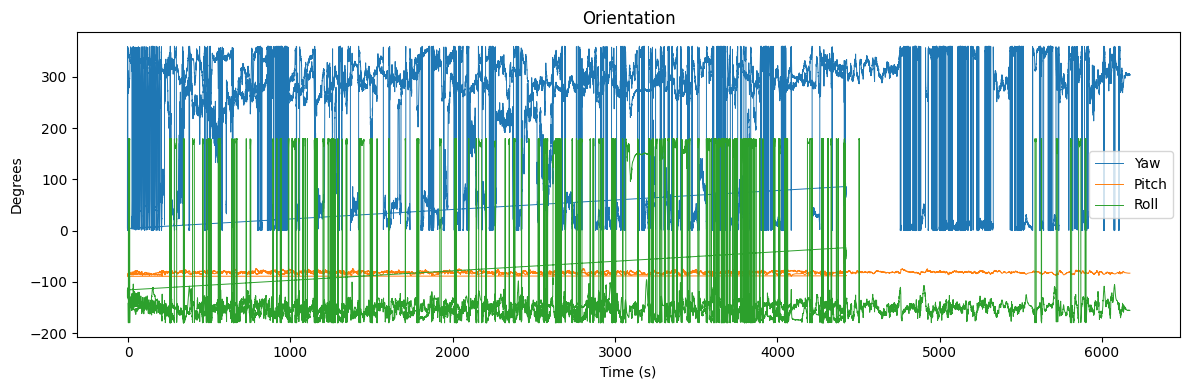

In [17]:
# ---- Figure 6: Orientation (Yaw/Pitch/Roll) --------------------------------
fig6, ax6 = plt.subplots(figsize=(12, 4))
ax6.plot(df["TIME (s)"], df["ORIENTATION (Yaw) (°)"], label="Yaw", linewidth=0.7)
ax6.plot(df["TIME (s)"], df["ORIENTATION (Pitch) (°)"], label="Pitch", linewidth=0.7)
ax6.plot(df["TIME (s)"], df["ORIENTATION (Roll ) (°)"], label="Roll", linewidth=0.7)
ax6.set_xlabel("Time (s)")
ax6.set_ylabel("Degrees")
ax6.set_title("Orientation")
ax6.legend()
fig6.tight_layout()


plt.show()

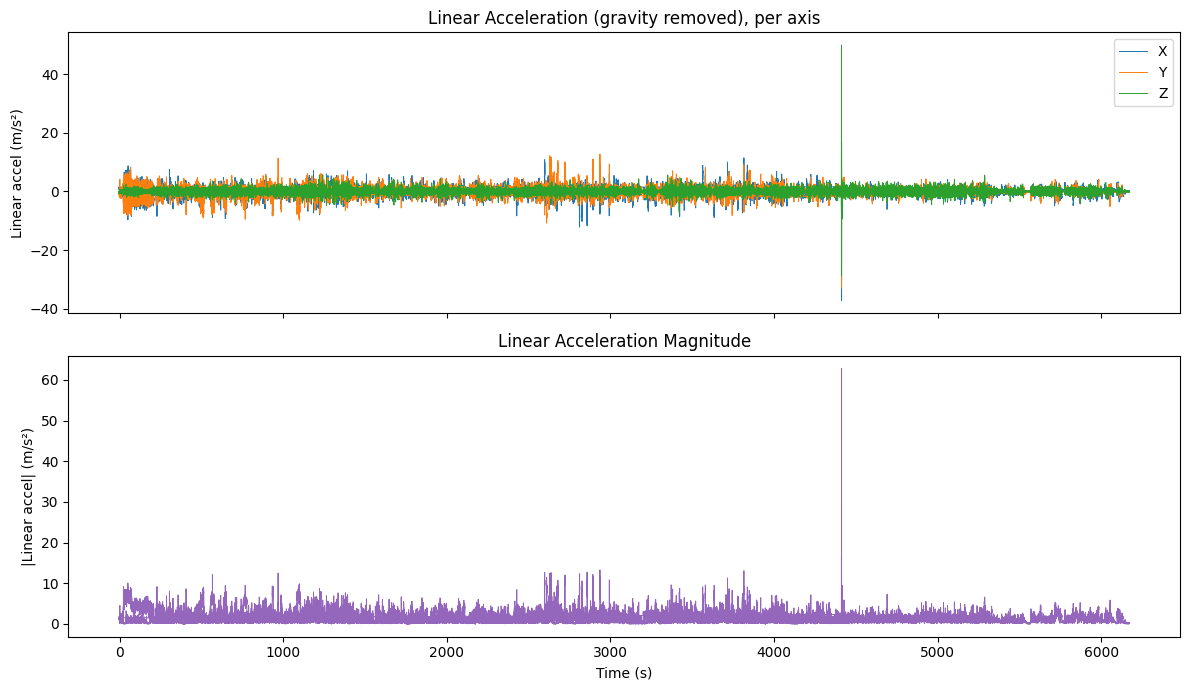

In [18]:
"""
Compute linear acceleration (gravity removed) from the accelerometer + gravity
columns in S-M.csv, and plot it.

The phone's ACCELEROMETER reading already includes gravity (~9.8 m/s^2
pulling toward the earth). The GRAVITY X/Y/Z columns are the sensor's own
estimate of just that gravity component (same units, same axes). Subtracting
gravity from the raw accelerometer reading, axis by axis, leaves just the
"linear acceleration" -- i.e. acceleration from actual motion (speeding up,
braking, turning), with gravity's contribution removed:

    linear_accel = accelerometer - gravity

Usage:
    pip install pandas numpy matplotlib
    python linear_acceleration.py
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Load data --------------------------------------------------------
csv_path = "S-M.csv"
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

t = (df["TIME SINCE START (ms)"] - df["TIME SINCE START (ms)"].iloc[0]) / 1000.0

# ---- Remove gravity, axis by axis --------------------------------------
lin_acc_x = df["ACCELEROMETER X (m/s)"] - df["GRAVITY X (m/s)"]
lin_acc_y = df["ACCELEROMETER Y (m/s)"] - df["GRAVITY Y (m/s)"]
lin_acc_z = df["ACCELEROMETER Z (m/s)"] - df["GRAVITY Z (m/s)"]

# Overall magnitude of the gravity-free (linear) acceleration
lin_acc_mag = np.sqrt(lin_acc_x**2 + lin_acc_y**2 + lin_acc_z**2)

# ---- Plot ----------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(t, lin_acc_x, label="X", linewidth=0.7)
axes[0].plot(t, lin_acc_y, label="Y", linewidth=0.7)
axes[0].plot(t, lin_acc_z, label="Z", linewidth=0.7)
axes[0].set_ylabel("Linear accel (m/s²)")
axes[0].set_title("Linear Acceleration (gravity removed), per axis")
axes[0].legend()

axes[1].plot(t, lin_acc_mag, color="tab:purple", linewidth=0.7)
axes[1].set_ylabel("|Linear accel| (m/s²)")
axes[1].set_xlabel("Time (s)")
axes[1].set_title("Linear Acceleration Magnitude")

fig.tight_layout()
plt.show()

Filtering X axis ...
Filtering Y axis ...
Filtering Z axis ...
Filtering magnitude ...


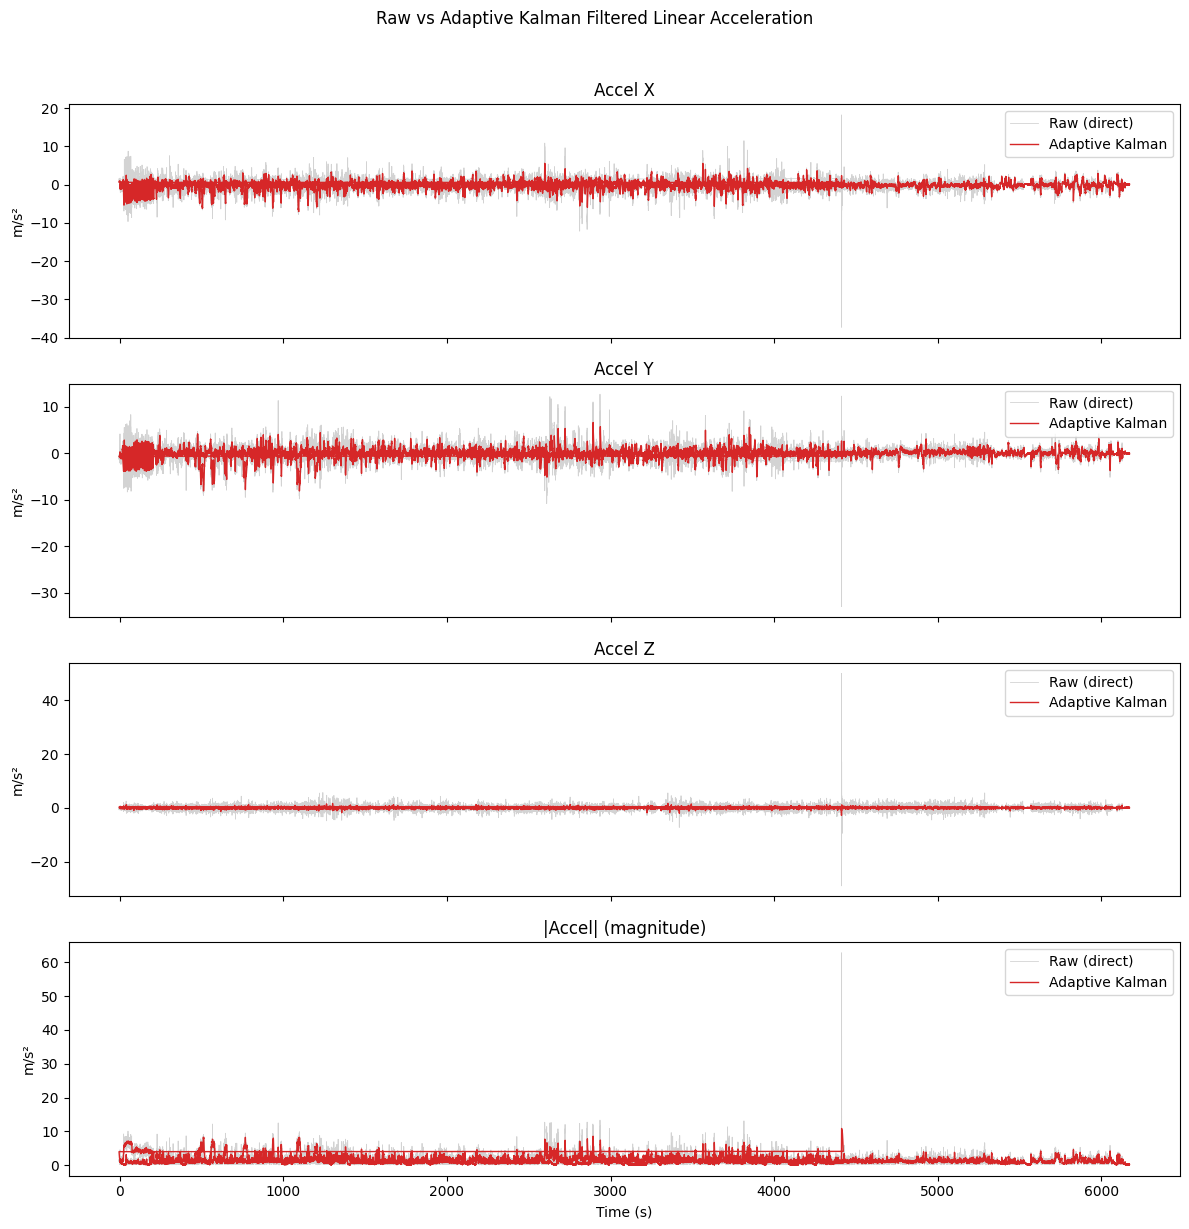

In [19]:
"""
Compare RAW (direct) linear acceleration vs. an Adaptive-Kalman-filtered
version of the same signal.

Pipeline:
    1. Remove gravity from the accelerometer reading -> linear acceleration
       (see linear_acceleration.py for details on this step).
    2. Run each axis (X, Y, Z) and the magnitude through a 1D Adaptive
       Kalman Filter (AKF) that smooths the noisy signal and automatically
       re-estimates its measurement noise R from the innovation sequence
       (instead of relying on one fixed, hand-picked R).
    3. Plot raw vs. filtered, overlaid, so you can see what the AKF removed.

Usage:
    pip install pandas numpy matplotlib
    python compare_raw_vs_adaptive_kalman.py
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Load data & compute raw linear acceleration (gravity removed)
# ============================================================
csv_path = "S-M.csv"
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

t = ((df["TIME SINCE START (ms)"] - df["TIME SINCE START (ms)"].iloc[0]) / 1000.0).to_numpy()

lin_acc_x = (df["ACCELEROMETER X (m/s)"] - df["GRAVITY X (m/s)"]).to_numpy()
lin_acc_y = (df["ACCELEROMETER Y (m/s)"] - df["GRAVITY Y (m/s)"]).to_numpy()
lin_acc_z = (df["ACCELEROMETER Z (m/s)"] - df["GRAVITY Z (m/s)"]).to_numpy()
lin_acc_mag = np.sqrt(lin_acc_x**2 + lin_acc_y**2 + lin_acc_z**2)


# ============================================================
# 2. 1D Adaptive Kalman Filter
# ============================================================
class AdaptiveKalman1D:
    """
    Simple scalar Kalman filter with a random-walk model:
        x_k = x_{k-1} + w,   w ~ N(0, Q)     (true signal barely changes step-to-step)
        z_k = x_k + v,       v ~ N(0, R)     (noisy sensor reading)

    R (measurement noise) is re-estimated online from the innovation
    sequence's own variance over a sliding window (innovation-based
    adaptive estimation), instead of being fixed up front. This lets
    the filter trust the sensor more/less as its noise level changes.
    """

    def __init__(self, x0=0.0, P0=1.0, Q=0.01, R=1.0, window=30, alpha=0.97):
        self.x = x0
        self.P = P0
        self.Q = Q
        self.R = R
        self.window = window
        self.alpha = alpha
        self.innovations = []

    def step(self, z):
        # ---- predict ----
        x_pred = self.x
        P_pred = self.P + self.Q

        # ---- update ----
        y = z - x_pred                      # innovation
        S = P_pred + self.R                 # innovation variance
        K = P_pred / S                      # Kalman gain
        self.x = x_pred + K * y
        self.P = (1 - K) * P_pred

        # ---- adapt R from recent innovation variance ----
        self.innovations.append(y)
        if len(self.innovations) > self.window:
            self.innovations.pop(0)
        if len(self.innovations) >= 5:
            innov_var = np.var(self.innovations)
            R_new = max(innov_var - P_pred, 1e-4)
            self.R = self.alpha * self.R + (1 - self.alpha) * R_new

        return self.x


def run_akf(signal, **kwargs):
    akf = AdaptiveKalman1D(x0=signal[0], **kwargs)
    out = np.empty(len(signal))
    for i, z in enumerate(signal):
        out[i] = akf.step(z)
    return out


print("Filtering X axis ...")
akf_x = run_akf(lin_acc_x, Q=0.01, R=2.0)
print("Filtering Y axis ...")
akf_y = run_akf(lin_acc_y, Q=0.01, R=2.0)
print("Filtering Z axis ...")
akf_z = run_akf(lin_acc_z, Q=0.01, R=2.0)
print("Filtering magnitude ...")
akf_mag = run_akf(lin_acc_mag, Q=0.01, R=2.0)


# ============================================================
# 3. Plot: raw (direct) vs Adaptive-Kalman-filtered, side by side
# ============================================================
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

pairs = [
    ("Accel X", lin_acc_x, akf_x),
    ("Accel Y", lin_acc_y, akf_y),
    ("Accel Z", lin_acc_z, akf_z),
    ("|Accel| (magnitude)", lin_acc_mag, akf_mag),
]

for ax, (label, raw, filt) in zip(axes, pairs):
    ax.plot(t, raw, color="lightgray", linewidth=0.6, label="Raw (direct)")
    ax.plot(t, filt, color="tab:red", linewidth=1.0, label="Adaptive Kalman")
    ax.set_ylabel("m/s²")
    ax.set_title(label)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Raw vs Adaptive Kalman Filtered Linear Acceleration", y=1.02)
fig.tight_layout()
plt.show()


Filtering Accel X ...
Filtering Accel Y ...
Filtering Accel Z ...
Filtering |Accel| (magnitude) ...


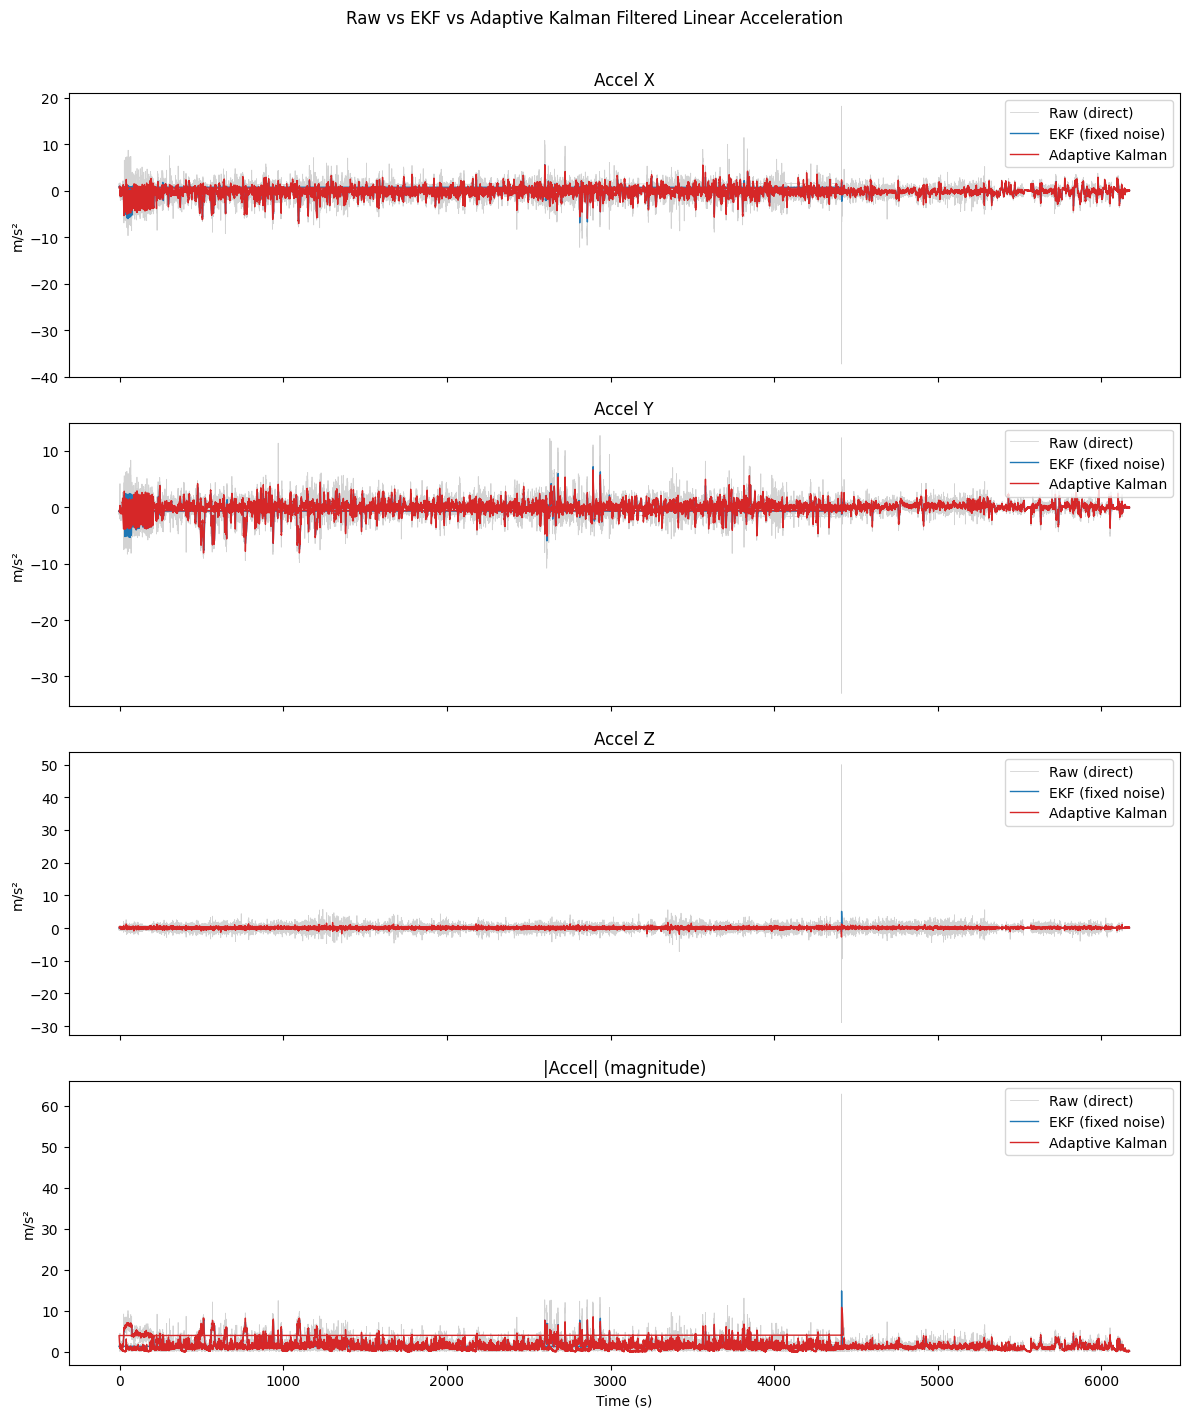

In [20]:
"""
Compare RAW (direct) linear acceleration vs an Extended Kalman Filter (EKF)
vs an Adaptive Kalman Filter (AKF) applied to the same signal.

Pipeline:
    1. Remove gravity from the accelerometer reading -> linear acceleration
       (raw_x = accelerometer_x - gravity_x, etc.)
    2. Run each axis (X, Y, Z) and the magnitude through:
         - EKF: fixed process/measurement noise (Q, R), written in the
           general "predict with f()/F, update with h()/H" EKF form so the
           same class works for nonlinear models too (here f and h happen
           to be the identity, i.e. this reduces to a plain 1D Kalman
           filter -- included as the non-adaptive baseline to compare
           against the adaptive version).
         - AKF: same model, but re-estimates R online from the innovation
           sequence (innovation-based adaptive estimation), so it isn't
           locked to one fixed noise guess.
    3. Plot raw vs EKF vs AKF together so you can see what each one removes.

Usage:
    pip install pandas numpy matplotlib
    python compare_raw_ekf_akf.py
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Load data & compute raw linear acceleration (gravity removed)
# ============================================================
csv_path = "S-M.csv"
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

t = ((df["TIME SINCE START (ms)"] - df["TIME SINCE START (ms)"].iloc[0]) / 1000.0).to_numpy()

lin_acc_x = (df["ACCELEROMETER X (m/s)"] - df["GRAVITY X (m/s)"]).to_numpy()
lin_acc_y = (df["ACCELEROMETER Y (m/s)"] - df["GRAVITY Y (m/s)"]).to_numpy()
lin_acc_z = (df["ACCELEROMETER Z (m/s)"] - df["GRAVITY Z (m/s)"]).to_numpy()
lin_acc_mag = np.sqrt(lin_acc_x**2 + lin_acc_y**2 + lin_acc_z**2)


# ============================================================
# 2a. Extended Kalman Filter (1D, fixed Q/R)
# ============================================================
class EKF1D:
    """
    1D Kalman filter written in general EKF form:
        predict: x_pred = f(x);         P_pred = F * P * F + Q
        update:  y = z - h(x_pred);     S = H * P_pred * H + R
                 K = P_pred * H / S
                 x = x_pred + K*y;      P = (1 - K*H) * P_pred

    Here f(x) = x and h(x) = x (their Jacobians F = H = 1), so this
    reduces to a plain scalar Kalman filter -- kept in EKF form so the
    exact same class can drop in a nonlinear f()/h() later. Q and R
    are FIXED (hand-tuned), unlike the adaptive version below.
    """

    def __init__(self, x0=0.0, P0=1.0, Q=0.01, R=1.0):
        self.x = x0
        self.P = P0
        self.Q = Q
        self.R = R

    def step(self, z):
        # ---- predict ----
        F = 1.0                      # Jacobian of f(x) = x
        x_pred = self.x              # f(x)
        P_pred = F * self.P * F + self.Q

        # ---- update ----
        H = 1.0                      # Jacobian of h(x) = x
        y = z - H * x_pred           # innovation
        S = H * P_pred * H + self.R  # innovation variance
        K = P_pred * H / S           # Kalman gain
        self.x = x_pred + K * y
        self.P = (1 - K * H) * P_pred
        return self.x


def run_ekf(signal, Q=0.01, R=2.0):
    ekf = EKF1D(x0=signal[0], Q=Q, R=R)
    out = np.empty(len(signal))
    for i, z in enumerate(signal):
        out[i] = ekf.step(z)
    return out


# ============================================================
# 2b. Adaptive Kalman Filter (1D, online-estimated R)
# ============================================================
class AdaptiveKalman1D:
    """
    Same random-walk model as EKF1D, but R (measurement noise) is
    re-estimated online from the variance of recent innovations over a
    sliding window (innovation-based adaptive estimation), instead of
    being fixed up front.
    """

    def __init__(self, x0=0.0, P0=1.0, Q=0.01, R=1.0, window=30, alpha=0.97):
        self.x = x0
        self.P = P0
        self.Q = Q
        self.R = R
        self.window = window
        self.alpha = alpha
        self.innovations = []

    def step(self, z):
        # ---- predict ----
        x_pred = self.x
        P_pred = self.P + self.Q

        # ---- update ----
        y = z - x_pred
        S = P_pred + self.R
        K = P_pred / S
        self.x = x_pred + K * y
        self.P = (1 - K) * P_pred

        # ---- adapt R from recent innovation variance ----
        self.innovations.append(y)
        if len(self.innovations) > self.window:
            self.innovations.pop(0)
        if len(self.innovations) >= 5:
            innov_var = np.var(self.innovations)
            R_new = max(innov_var - P_pred, 1e-4)
            self.R = self.alpha * self.R + (1 - self.alpha) * R_new

        return self.x


def run_akf(signal, Q=0.01, R=2.0, window=30, alpha=0.97):
    akf = AdaptiveKalman1D(x0=signal[0], Q=Q, R=R, window=window, alpha=alpha)
    out = np.empty(len(signal))
    for i, z in enumerate(signal):
        out[i] = akf.step(z)
    return out


# ============================================================
# 3. Run both filters on every axis + magnitude
# ============================================================
signals = {
    "Accel X": lin_acc_x,
    "Accel Y": lin_acc_y,
    "Accel Z": lin_acc_z,
    "|Accel| (magnitude)": lin_acc_mag,
}

results = {}
for label, raw in signals.items():
    print(f"Filtering {label} ...")
    results[label] = {
        "raw": raw,
        "ekf": run_ekf(raw, Q=0.01, R=2.0),
        "akf": run_akf(raw, Q=0.01, R=2.0, window=30, alpha=0.97),
    }


# ============================================================
# 4. Plot: raw vs EKF vs Adaptive Kalman, per axis + magnitude
# ============================================================
fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)

for ax, (label, r) in zip(axes, results.items()):
    ax.plot(t, r["raw"], color="lightgray", linewidth=0.6, label="Raw (direct)")
    ax.plot(t, r["ekf"], color="tab:blue", linewidth=1.0, label="EKF (fixed noise)")
    ax.plot(t, r["akf"], color="tab:red", linewidth=1.0, label="Adaptive Kalman")
    ax.set_ylabel("m/s²")
    ax.set_title(label)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Raw vs EKF vs Adaptive Kalman Filtered Linear Acceleration", y=1.01)
fig.tight_layout()
plt.show()

Timestamp check: 0 backwards steps after using DATE (was 1 backwards step of ~4427s when using TIME SINCE START).
Accel X: 49 spike(s) removed by Hampel filter
Accel Y: 35 spike(s) removed by Hampel filter
Accel Z: 37 spike(s) removed by Hampel filter
|Accel| (magnitude): 84 spike(s) removed by Hampel filter
Pipeline runtime: 19.29s for 105,974 rows x 4 signals


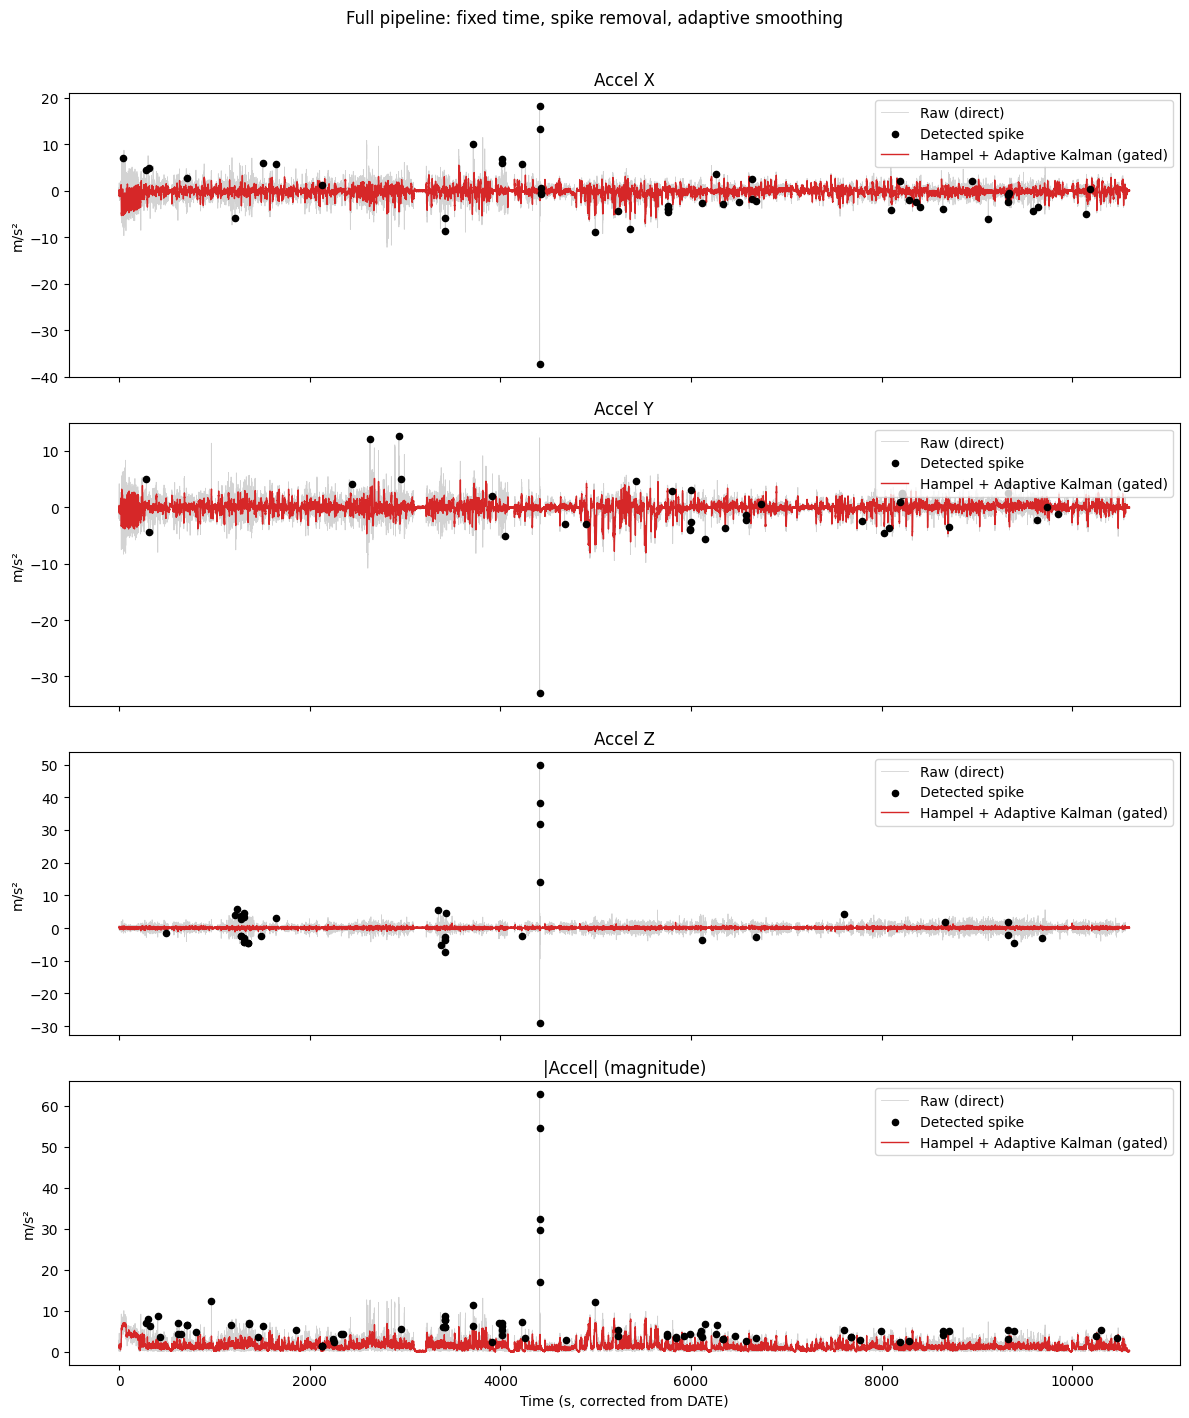

In [21]:
"""
Full cleaning pipeline for the linear (gravity-removed) acceleration signal:

    1. Fix elapsed time using the DATE column (the TIME SINCE START counter
       resets partway through this log -- see notes below).
    2. Hampel filter: catches and removes isolated spikes/glitches
       (e.g. the ~63 m/s^2 outlier in this dataset) without blurring real,
       fast motion the way a low-pass filter would.
    3. Adaptive Kalman Filter with innovation gating: smooths the everyday
       sensor jitter, re-tunes its own noise estimate (R) over time, and
       refuses to be dragged by any leftover outlier it sees.

Usage:
    pip install pandas numpy matplotlib
    python full_pipeline.py
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Load data
# ============================================================
csv_path = "S-M.csv"
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

# ---- Fix elapsed time using DATE instead of the resetting counter ----
# The DATE column format is "YYYY-MO-DD HH-MI-SS:SSS" (colon before ms).
dates = pd.to_datetime(df["DATE (YYYY-MO-DD HH-MI-SS_SSS)"], format="%Y-%m-%d %H:%M:%S:%f")
t = (dates - dates.iloc[0]).dt.total_seconds().to_numpy()

# Sanity check: elapsed time should now be strictly increasing.
n_backwards = (np.diff(t) < 0).sum()
print(f"Timestamp check: {n_backwards} backwards steps after using DATE "
      f"(was 1 backwards step of ~4427s when using TIME SINCE START).")

# ---- Raw linear acceleration (gravity removed) ----
lin_acc_x = (df["ACCELEROMETER X (m/s)"] - df["GRAVITY X (m/s)"]).to_numpy()
lin_acc_y = (df["ACCELEROMETER Y (m/s)"] - df["GRAVITY Y (m/s)"]).to_numpy()
lin_acc_z = (df["ACCELEROMETER Z (m/s)"] - df["GRAVITY Z (m/s)"]).to_numpy()
lin_acc_mag = np.sqrt(lin_acc_x**2 + lin_acc_y**2 + lin_acc_z**2)


# ============================================================
# 2. Hampel filter (vectorized -- fast even on 100k+ rows)
# ============================================================
def hampel_filter(x, window=31, n_sigmas=8.0):
    """
    Replace isolated outliers with the local rolling median.

    For each point, compares it to the median of a small window around it.
    If it's more than `n_sigmas` robust-standard-deviations away (using the
    Median Absolute Deviation, MAD, scaled to behave like a std under a
    normal distribution), it's replaced by the local median. Everything
    else is left completely untouched -- unlike a low-pass filter, this
    doesn't blur or smear real fast motion, only isolated spikes.

    Implemented with pandas' rolling().median(), which is a fast compiled
    routine -- no per-sample Python loop, so this scales fine to 100k+ rows.
    """
    s = pd.Series(x)
    k = 1.4826  # scales MAD to be comparable to a standard deviation
    rolling_median = s.rolling(window, center=True, min_periods=1).median()
    abs_dev = (s - rolling_median).abs()
    mad = abs_dev.rolling(window, center=True, min_periods=1).median()
    threshold = n_sigmas * k * mad
    is_outlier = (abs_dev > threshold).to_numpy()

    cleaned = s.to_numpy().copy()
    cleaned[is_outlier] = rolling_median.to_numpy()[is_outlier]
    return cleaned, is_outlier


# ============================================================
# 3. Adaptive Kalman Filter with innovation gating
# ============================================================
class AdaptiveKalmanGated:
    """
    Same random-walk Adaptive Kalman Filter as before (re-estimates R from
    the innovation sequence), plus one addition: innovation gating. If a
    new measurement disagrees with the prediction by more than `gate`
    standard deviations, it's treated as an outlier -- the filter keeps
    its prediction and skips the update (and does NOT let that sample
    pollute its running noise estimate). This is a permanent safety net,
    independent of the one-time Hampel cleanup above.
    """

    def __init__(self, x0=0.0, P0=1.0, Q=0.01, R=1.0, window=30, alpha=0.97, gate=5.0):
        self.x = x0
        self.P = P0
        self.Q = Q
        self.R = R
        self.window = window
        self.alpha = alpha
        self.gate = gate
        self.innovations = []

    def step(self, z):
        # ---- predict ----
        x_pred = self.x
        P_pred = self.P + self.Q

        # ---- innovation + gate check ----
        y = z - x_pred
        S = P_pred + self.R
        if abs(y) > self.gate * np.sqrt(S):
            # Reject: too far from prediction to trust. Keep predicting,
            # don't update state/covariance, don't pollute R estimation.
            self.x, self.P = x_pred, P_pred
            return self.x

        # ---- update ----
        K = P_pred / S
        self.x = x_pred + K * y
        self.P = (1 - K) * P_pred

        # ---- adapt R from recent (non-rejected) innovation variance ----
        self.innovations.append(y)
        if len(self.innovations) > self.window:
            self.innovations.pop(0)
        if len(self.innovations) >= 5:
            innov_var = np.var(self.innovations)
            R_new = max(innov_var - P_pred, 1e-4)
            self.R = self.alpha * self.R + (1 - self.alpha) * R_new

        return self.x


def run_akf_gated(signal, **kwargs):
    akf = AdaptiveKalmanGated(x0=signal[0], **kwargs)
    out = np.empty(len(signal))
    for i, z in enumerate(signal):
        out[i] = akf.step(z)
    return out


# ============================================================
# 4. Run the full pipeline on X, Y, Z and magnitude
# ============================================================
signals = {
    "Accel X": lin_acc_x,
    "Accel Y": lin_acc_y,
    "Accel Z": lin_acc_z,
    "|Accel| (magnitude)": lin_acc_mag,
}

results = {}
t0 = time.time()
for label, raw in signals.items():
    cleaned, outlier_mask = hampel_filter(raw, window=31, n_sigmas=8.0)
    filtered = run_akf_gated(cleaned, Q=0.01, R=2.0, window=30, alpha=0.97, gate=5.0)
    results[label] = {"raw": raw, "outliers": outlier_mask, "filtered": filtered}
    print(f"{label}: {outlier_mask.sum()} spike(s) removed by Hampel filter")
print(f"Pipeline runtime: {time.time() - t0:.2f}s for {len(df):,} rows x 4 signals")


# ============================================================
# 5. Plot: raw (with detected outliers marked) vs final cleaned+filtered
# ============================================================
fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)

for ax, (label, r) in zip(axes, results.items()):
    ax.plot(t, r["raw"], color="lightgray", linewidth=0.6, label="Raw (direct)")
    if r["outliers"].any():
        ax.scatter(t[r["outliers"]], r["raw"][r["outliers"]],
                   color="black", s=20, zorder=5, label="Detected spike")
    ax.plot(t, r["filtered"], color="tab:red", linewidth=1.0,
            label="Hampel + Adaptive Kalman (gated)")
    ax.set_ylabel("m/s²")
    ax.set_title(label)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (s, corrected from DATE)")
fig.suptitle("Full pipeline: fixed time, spike removal, adaptive smoothing", y=1.01)
fig.tight_layout()
plt.show()

Spikes removed per channel:
  Accel X   : 49
  Accel Y   : 35
  Accel Z   : 37
  Gyro Yaw  : 74
  Gyro Pitch: 288
  Gyro Roll : 12
  Mag X     : 157
  Mag Y     : 126
  Mag Z     : 208

Adaptive Kalman runtime (all 9 channels, 105,974 rows): 3.91s


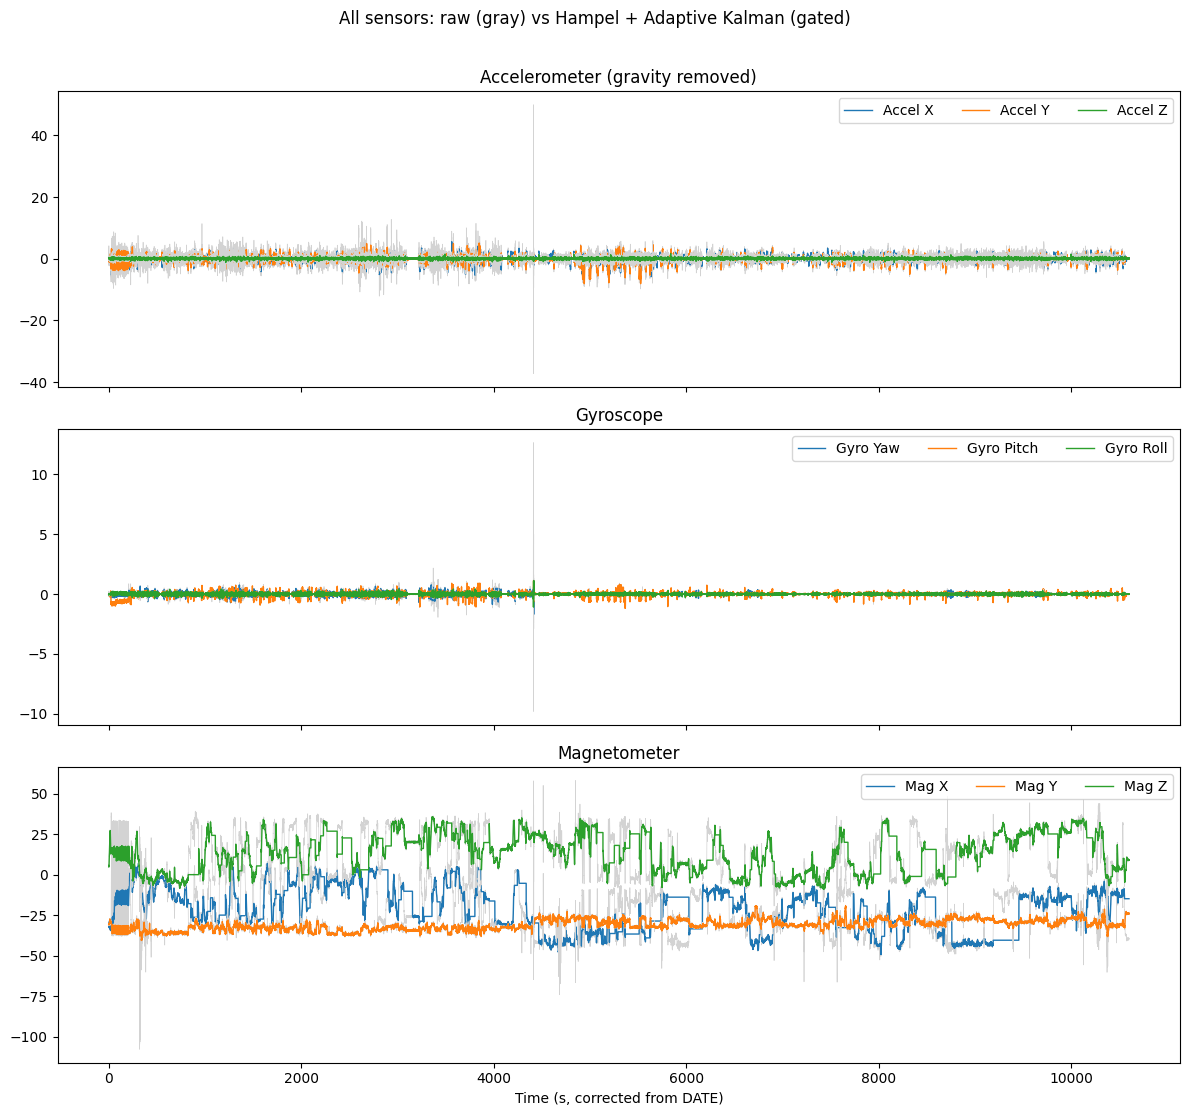

In [1]:
"""
Run the full cleaning pipeline (Hampel spike removal + Adaptive Kalman
smoothing with innovation gating) across ALL raw IMU channels at once:
accelerometer (gravity removed), gyroscope, and magnetometer -- 9 channels
total, all processed together instead of one at a time.

The Adaptive Kalman step is vectorized across channels: instead of looping
over each sensor separately (9 separate passes over ~106k rows), one single
time-loop updates all 9 channels' state simultaneously using numpy array
ops -- much faster than 9 independent Python loops.

Note on real-time use: Hampel needs a window of samples *around* each point
(including a few samples after it), so it's fine for offline cleaning but
can't run in true real-time. The Adaptive Kalman's innovation gate only
ever looks backward, so it's the one safe to run live on the phone; Hampel
here is best thought of as an offline/training-time cleanup step.

Usage:
    pip install pandas numpy matplotlib
    python all_sensors_pipeline.py
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Load data & fix timestamps (DATE column, not the resetting counter)
# ============================================================
csv_path = "S-M.csv"
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

dates = pd.to_datetime(df["DATE (YYYY-MO-DD HH-MI-SS_SSS)"], format="%Y-%m-%d %H:%M:%S:%f")
t = (dates - dates.iloc[0]).dt.total_seconds().to_numpy()

# ============================================================
# 2. Assemble all raw channels into one matrix
# ============================================================
channel_names = [
    "Accel X", "Accel Y", "Accel Z",
    "Gyro Yaw", "Gyro Pitch", "Gyro Roll",
    "Mag X", "Mag Y", "Mag Z",
]

accel_x = (df["ACCELEROMETER X (m/s)"] - df["GRAVITY X (m/s)"]).to_numpy()
accel_y = (df["ACCELEROMETER Y (m/s)"] - df["GRAVITY Y (m/s)"]).to_numpy()
accel_z = (df["ACCELEROMETER Z (m/s)"] - df["GRAVITY Z (m/s)"]).to_numpy()
gyro_yaw = df["GYROSCOPE Yaw (rad/s)"].to_numpy()
gyro_pitch = df["GYROSCOPE Pitch (rad/s)"].to_numpy()
gyro_roll = df["GYROSCOPE Roll (rad/s)"].to_numpy()
mag_x = df["MAGNETIC FIELD X (μT)"].to_numpy()
mag_y = df["MAGNETIC FIELD Y (μT)"].to_numpy()
mag_z = df["MAGNETIC FIELD Z (μT)"].to_numpy()

Z_raw = np.column_stack([accel_x, accel_y, accel_z,
                          gyro_yaw, gyro_pitch, gyro_roll,
                          mag_x, mag_y, mag_z])  # shape (N, 9)
N, n_channels = Z_raw.shape


# ============================================================
# 3. Hampel filter, applied per channel (still vectorized per column --
#    pandas' rolling median is a fast compiled routine, no Python loop)
# ============================================================
def hampel_filter(x, window=31, n_sigmas=8.0):
    s = pd.Series(x)
    k = 1.4826
    rolling_median = s.rolling(window, center=True, min_periods=1).median()
    abs_dev = (s - rolling_median).abs()
    mad = abs_dev.rolling(window, center=True, min_periods=1).median()
    threshold = n_sigmas * k * mad
    is_outlier = (abs_dev > threshold).to_numpy()
    cleaned = s.to_numpy().copy()
    cleaned[is_outlier] = rolling_median.to_numpy()[is_outlier]
    return cleaned, is_outlier


Z_cleaned = np.empty_like(Z_raw)
outlier_counts = {}

# Per-channel Hampel settings: accelerometer/gyro change fast, so a short
# window (31 samples, ~3s) works well. The magnetometer changes much more
# slowly and smoothly (e.g. during a turn), so a short window falsely
# flags real gradual drift as a run of outliers -- it needs a much wider
# window and higher threshold to only catch genuinely abrupt changes.
hampel_params = {
    "Accel X": (31, 8.0), "Accel Y": (31, 8.0), "Accel Z": (31, 8.0),
    "Gyro Yaw": (31, 8.0), "Gyro Pitch": (31, 8.0), "Gyro Roll": (31, 8.0),
    "Mag X": (151, 10.0), "Mag Y": (31, 8.0), "Mag Z": (151, 10.0),
    # Mag Y measured to behave more like the fast-changing channels here
    # (checked empirically -- it doesn't have Mag X/Z's slow-drift issue)
}

for i, name in enumerate(channel_names):
    window, n_sigmas = hampel_params[name]
    cleaned, mask = hampel_filter(Z_raw[:, i], window=window, n_sigmas=n_sigmas)
    Z_cleaned[:, i] = cleaned
    outlier_counts[name] = mask.sum()

print("Spikes removed per channel:")
for name, count in outlier_counts.items():
    print(f"  {name:10s}: {count}")


# ============================================================
# 4. Adaptive Kalman with innovation gating -- vectorized across ALL
#    channels in one single time loop (not one loop per channel)
# ============================================================
def run_adaptive_kalman_multi(Z, Q=0.01, R0=2.0, window=30, alpha=0.97, gate=5.0):
    """
    Z: (N, n_channels) array, already Hampel-cleaned.
    Runs one random-walk Adaptive Kalman filter per channel, but all
    channels are updated together at each time step using numpy array
    ops -- a single Python loop of length N instead of n_channels
    separate loops.
    """
    N, n_ch = Z.shape
    x = Z[0].copy()                      # initial state per channel
    P = np.ones(n_ch)                    # initial uncertainty per channel
    Qv = np.full(n_ch, Q)
    Rv = np.full(n_ch, R0)

    out = np.empty((N, n_ch))
    innov_buffer = np.zeros((window, n_ch))
    buf_idx = 0
    buf_count = 0

    for k in range(N):
        z = Z[k]

        # ---- predict (random walk model, per channel) ----
        x_pred = x
        P_pred = P + Qv

        # ---- innovation + gate (vectorized across channels) ----
        y = z - x_pred
        S = P_pred + Rv
        gated = np.abs(y) > gate * np.sqrt(S)

        # ---- update (skip channels that failed the gate) ----
        K = P_pred / S
        x = np.where(gated, x_pred, x_pred + K * y)
        P = np.where(gated, P_pred, (1 - K) * P_pred)

        # ---- adapt R per channel from recent (non-rejected) innovations ----
        innov_buffer[buf_idx] = np.where(gated, 0.0, y)  # gated channels contribute nothing this step
        buf_idx = (buf_idx + 1) % window
        buf_count = min(buf_count + 1, window)
        if buf_count >= 5:
            innov_var = innov_buffer[:buf_count].var(axis=0)
            R_new = np.maximum(innov_var - P_pred, 1e-4)
            Rv = alpha * Rv + (1 - alpha) * R_new

        out[k] = x

    return out


t0 = time.time()
Z_filtered = run_adaptive_kalman_multi(Z_cleaned, Q=0.01, R0=2.0, window=30, alpha=0.97, gate=5.0)
print(f"\nAdaptive Kalman runtime (all {n_channels} channels, {N:,} rows): {time.time()-t0:.2f}s")


# ============================================================
# 5. Plot: raw vs fully cleaned+filtered, grouped by sensor type
# ============================================================
groups = {
    "Accelerometer (gravity removed)": [0, 1, 2],
    "Gyroscope": [3, 4, 5],
    "Magnetometer": [6, 7, 8],
}

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

for ax, (title, idxs) in zip(axes, groups.items()):
    for i in idxs:
        ax.plot(t, Z_raw[:, i], color="lightgray", linewidth=0.5)
        ax.plot(t, Z_filtered[:, i], linewidth=1.0, label=channel_names[i])
    ax.set_title(title)
    ax.legend(loc="upper right", ncol=3)

axes[-1].set_xlabel("Time (s, corrected from DATE)")
fig.suptitle("All sensors: raw (gray) vs Hampel + Adaptive Kalman (gated)", y=1.01)
fig.tight_layout()
plt.show()

Adaptive Kalman runtime (all 9 channels, 105,974 rows): 4.55s


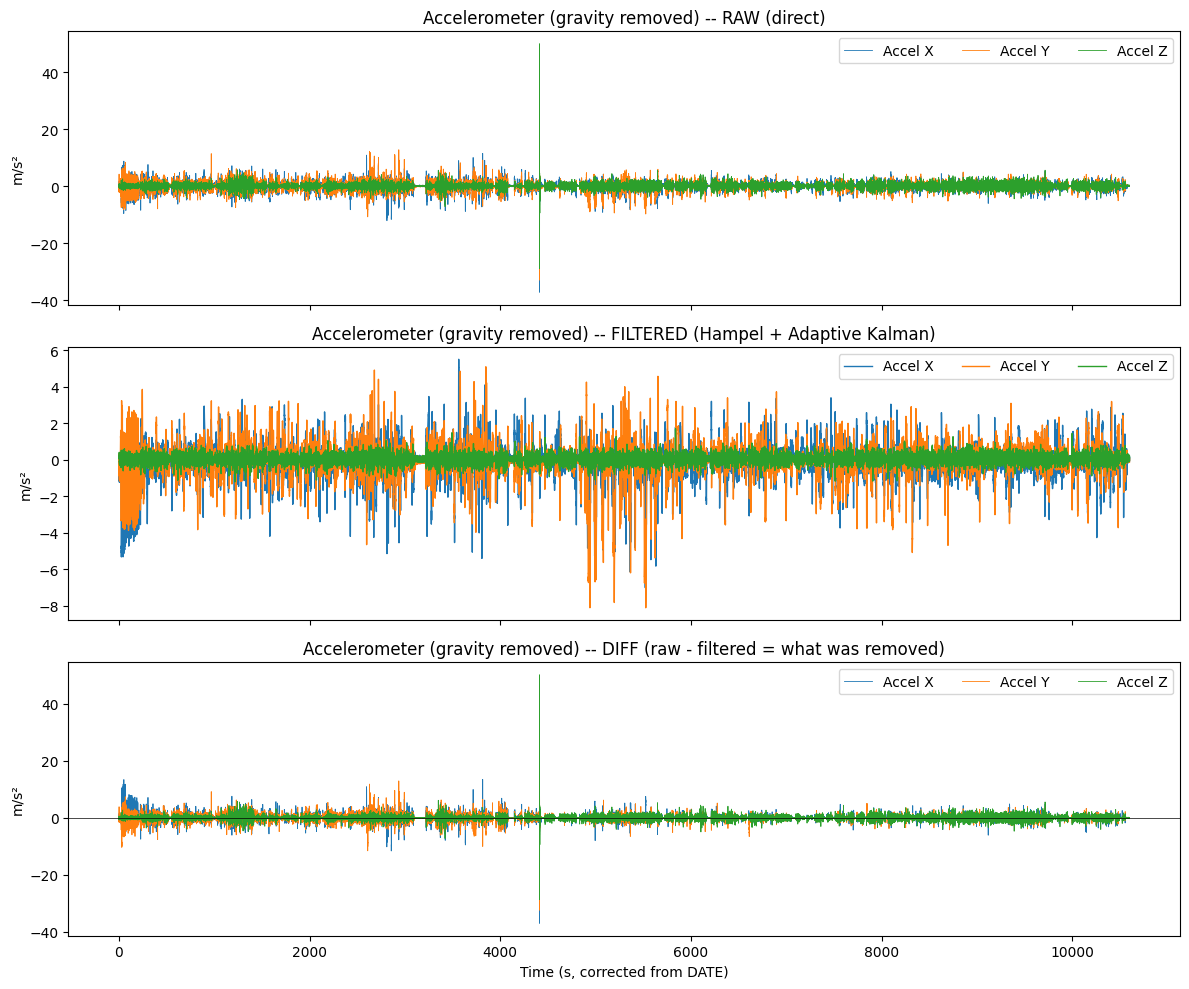

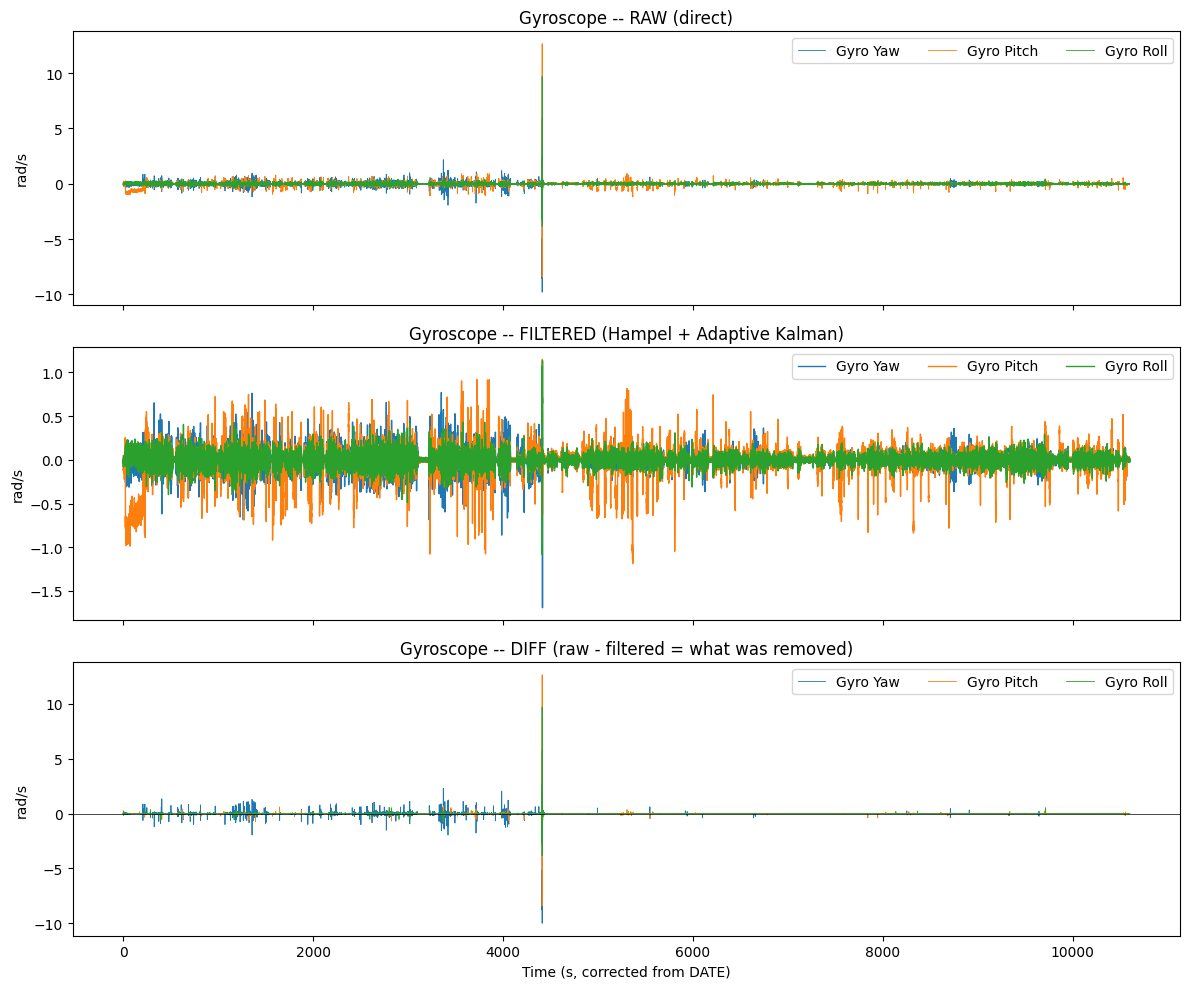

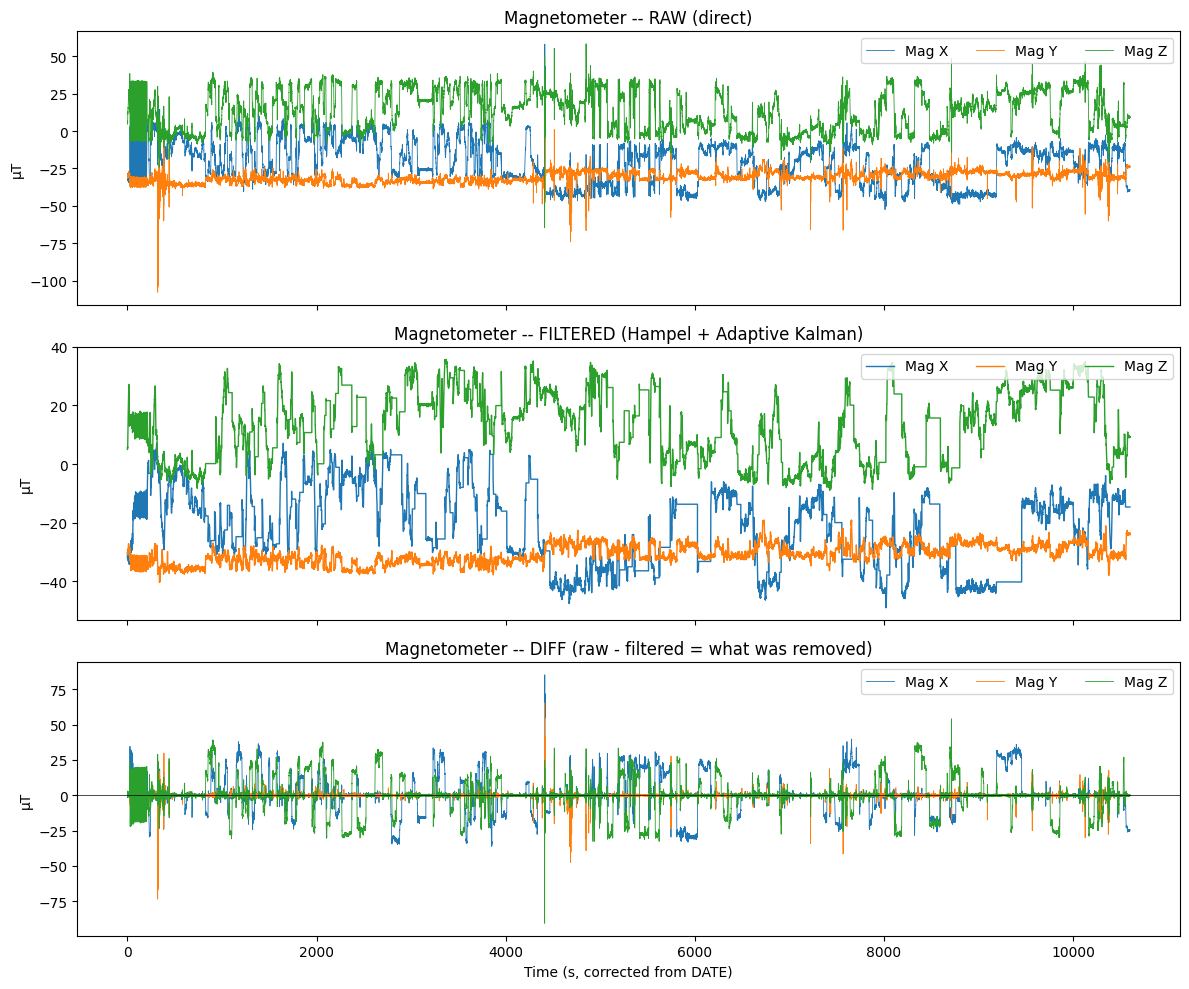

In [2]:
"""
Same pipeline as all_sensors_pipeline.py (Hampel spike removal + Adaptive
Kalman smoothing with innovation gating, across all 9 raw IMU channels),
but plotted so RAW, FILTERED, and the DIFFERENCE between them are shown
as three clearly separate panels per sensor group -- instead of overlaid
on the same axes -- so you can see exactly what the algorithm changed.

Usage:
    pip install pandas numpy matplotlib
    python raw_vs_filtered_diff.py
"""

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Load data & fix timestamps (DATE column, not the resetting counter)
# ============================================================
csv_path = "S-M.csv"
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

dates = pd.to_datetime(df["DATE (YYYY-MO-DD HH-MI-SS_SSS)"], format="%Y-%m-%d %H:%M:%S:%f")
t = (dates - dates.iloc[0]).dt.total_seconds().to_numpy()

# ============================================================
# 2. Assemble all raw channels into one matrix
# ============================================================
channel_names = [
    "Accel X", "Accel Y", "Accel Z",
    "Gyro Yaw", "Gyro Pitch", "Gyro Roll",
    "Mag X", "Mag Y", "Mag Z",
]

accel_x = (df["ACCELEROMETER X (m/s)"] - df["GRAVITY X (m/s)"]).to_numpy()
accel_y = (df["ACCELEROMETER Y (m/s)"] - df["GRAVITY Y (m/s)"]).to_numpy()
accel_z = (df["ACCELEROMETER Z (m/s)"] - df["GRAVITY Z (m/s)"]).to_numpy()
gyro_yaw = df["GYROSCOPE Yaw (rad/s)"].to_numpy()
gyro_pitch = df["GYROSCOPE Pitch (rad/s)"].to_numpy()
gyro_roll = df["GYROSCOPE Roll (rad/s)"].to_numpy()
mag_x = df["MAGNETIC FIELD X (μT)"].to_numpy()
mag_y = df["MAGNETIC FIELD Y (μT)"].to_numpy()
mag_z = df["MAGNETIC FIELD Z (μT)"].to_numpy()

Z_raw = np.column_stack([accel_x, accel_y, accel_z,
                          gyro_yaw, gyro_pitch, gyro_roll,
                          mag_x, mag_y, mag_z])  # shape (N, 9)
N, n_channels = Z_raw.shape


# ============================================================
# 3. Hampel filter (per-channel tuned -- magnetometer needs a wider
#    window since it changes more slowly/smoothly than accel/gyro)
# ============================================================
def hampel_filter(x, window=31, n_sigmas=8.0):
    s = pd.Series(x)
    k = 1.4826
    rolling_median = s.rolling(window, center=True, min_periods=1).median()
    abs_dev = (s - rolling_median).abs()
    mad = abs_dev.rolling(window, center=True, min_periods=1).median()
    threshold = n_sigmas * k * mad
    is_outlier = (abs_dev > threshold).to_numpy()
    cleaned = s.to_numpy().copy()
    cleaned[is_outlier] = rolling_median.to_numpy()[is_outlier]
    return cleaned, is_outlier


hampel_params = {
    "Accel X": (31, 8.0), "Accel Y": (31, 8.0), "Accel Z": (31, 8.0),
    "Gyro Yaw": (31, 8.0), "Gyro Pitch": (31, 8.0), "Gyro Roll": (31, 8.0),
    "Mag X": (151, 10.0), "Mag Y": (31, 8.0), "Mag Z": (151, 10.0),
}

Z_cleaned = np.empty_like(Z_raw)
for i, name in enumerate(channel_names):
    window, n_sigmas = hampel_params[name]
    cleaned, _ = hampel_filter(Z_raw[:, i], window=window, n_sigmas=n_sigmas)
    Z_cleaned[:, i] = cleaned


# ============================================================
# 4. Adaptive Kalman with innovation gating -- vectorized across
#    all channels in one time loop
# ============================================================
def run_adaptive_kalman_multi(Z, Q=0.01, R0=2.0, window=30, alpha=0.97, gate=5.0):
    N, n_ch = Z.shape
    x = Z[0].copy()
    P = np.ones(n_ch)
    Qv = np.full(n_ch, Q)
    Rv = np.full(n_ch, R0)

    out = np.empty((N, n_ch))
    innov_buffer = np.zeros((window, n_ch))
    buf_idx = 0
    buf_count = 0

    for k in range(N):
        z = Z[k]
        x_pred = x
        P_pred = P + Qv

        y = z - x_pred
        S = P_pred + Rv
        gated = np.abs(y) > gate * np.sqrt(S)

        K = P_pred / S
        x = np.where(gated, x_pred, x_pred + K * y)
        P = np.where(gated, P_pred, (1 - K) * P_pred)

        innov_buffer[buf_idx] = np.where(gated, 0.0, y)
        buf_idx = (buf_idx + 1) % window
        buf_count = min(buf_count + 1, window)
        if buf_count >= 5:
            innov_var = innov_buffer[:buf_count].var(axis=0)
            R_new = np.maximum(innov_var - P_pred, 1e-4)
            Rv = alpha * Rv + (1 - alpha) * R_new

        out[k] = x

    return out


t0 = time.time()
Z_filtered = run_adaptive_kalman_multi(Z_cleaned, Q=0.01, R0=2.0, window=30, alpha=0.97, gate=5.0)
print(f"Adaptive Kalman runtime (all {n_channels} channels, {N:,} rows): {time.time()-t0:.2f}s")

Z_diff = Z_raw - Z_filtered  # what the pipeline actually removed/changed


# ============================================================
# 5. Plot: RAW / FILTERED / DIFF as three separate panels, per sensor group
# ============================================================
groups = {
    "Accelerometer (gravity removed)": ([0, 1, 2], "m/s²"),
    "Gyroscope": ([3, 4, 5], "rad/s"),
    "Magnetometer": ([6, 7, 8], "μT"),
}

for title, (idxs, unit) in groups.items():
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    for i in idxs:
        axes[0].plot(t, Z_raw[:, i], linewidth=0.6, label=channel_names[i])
    axes[0].set_title(f"{title} -- RAW (direct)")
    axes[0].set_ylabel(unit)
    axes[0].legend(loc="upper right", ncol=3)

    for i in idxs:
        axes[1].plot(t, Z_filtered[:, i], linewidth=1.0, label=channel_names[i])
    axes[1].set_title(f"{title} -- FILTERED (Hampel + Adaptive Kalman)")
    axes[1].set_ylabel(unit)
    axes[1].legend(loc="upper right", ncol=3)

    for i in idxs:
        axes[2].plot(t, Z_diff[:, i], linewidth=0.6, label=channel_names[i])
    axes[2].axhline(0, color="black", linewidth=0.5)
    axes[2].set_title(f"{title} -- DIFF (raw - filtered = what was removed)")
    axes[2].set_ylabel(unit)
    axes[2].set_xlabel("Time (s, corrected from DATE)")
    axes[2].legend(loc="upper right", ncol=3)

    fig.tight_layout()

plt.show()

In [1]:
"""
Measures how much the Adaptive Kalman filter actually improves dead-reckoning
ACCURACY -- not just "does the signal look smoother", but "how much closer
does the estimated position get to real GPS" during simulated GNSS blackout
windows. This mirrors the CRSE / drift-percentage style metrics used in
INS/GNSS localisation papers (e.g. Onyekpe et al., Appl. Sci. 2021).

Method:
    1. Fix timestamps (DATE column), convert GPS lat/lon to local ENU meters
       -- this is our ground truth.
    2. Compute linear (gravity-removed) forward acceleration, in two versions:
         RAW      -- untouched
         FILTERED -- Hampel spike removal + Adaptive Kalman smoothing
    3. Pick several 10-second windows across the trip (simulated GNSS
       blackouts). For each window: dead-reckon position using ONLY
       acceleration + measured heading (non-holonomic: forward speed and
       heading only, no lateral slip) -- once with RAW accel, once with
       FILTERED accel. Everything else (heading, start position/speed) is
       identical between the two runs, so any accuracy difference is
       attributable to the filtering alone.
    4. Compare both dead-reckoned tracks against true GPS position at each
       second in the window. Report per-window and aggregate accuracy.

Usage:
    pip install pandas numpy matplotlib
    python adaptive_kalman_accuracy.py
"""

import numpy as np
import pandas as pd

# ============================================================
# 1. Load data, fix timestamps, ground-truth ENU position
# ============================================================
csv_path = "S-M.csv"
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

dates = pd.to_datetime(df["DATE (YYYY-MO-DD HH-MI-SS_SSS)"], format="%Y-%m-%d %H:%M:%S:%f")
t = (dates - dates.iloc[0]).dt.total_seconds().to_numpy()
dt_arr = np.diff(t, prepend=t[0])
dt_arr[0] = dt_arr[1] if len(dt_arr) > 1 else 0.1
dt_arr = np.clip(dt_arr, 1e-3, None)

R_EARTH = 6378137.0
lat0 = np.radians(df["GPS LATITUDE (degrees)"].iloc[0])
lon0 = np.radians(df["GPS LONGITUDE (degrees)"].iloc[0])
lat = np.radians(df["GPS LATITUDE (degrees)"])
lon = np.radians(df["GPS LONGITUDE (degrees)"])
gps_x = ((lon - lon0) * np.cos(lat0) * R_EARTH).to_numpy()
gps_y = ((lat - lat0) * R_EARTH).to_numpy()
gps_is_new = ((df["GPS LATITUDE (degrees)"].diff() != 0) |
              (df["GPS LONGITUDE (degrees)"].diff() != 0)).to_numpy().copy()
gps_is_new[0] = True

yaw_rad = np.radians(df["ORIENTATION (Yaw) (°)"].to_numpy())          # measured heading
gps_speed_ms = (df["GPS SPEED (Kmh)"] / 3.6).to_numpy()

accel_x_raw = (df["ACCELEROMETER X (m/s)"] - df["GRAVITY X (m/s)"]).to_numpy()

# ============================================================
# 2. Hampel + Adaptive Kalman (with gate) -- same pipeline as before
# ============================================================
def hampel_filter(x, window=31, n_sigmas=8.0):
    s = pd.Series(x)
    k = 1.4826
    rolling_median = s.rolling(window, center=True, min_periods=1).median()
    abs_dev = (s - rolling_median).abs()
    mad = abs_dev.rolling(window, center=True, min_periods=1).median()
    is_outlier = (abs_dev > n_sigmas * k * mad).to_numpy()
    cleaned = s.to_numpy().copy()
    cleaned[is_outlier] = rolling_median.to_numpy()[is_outlier]
    return cleaned


class AdaptiveKalmanGated:
    def __init__(self, x0, P0=1.0, Q=0.01, R=2.0, window=30, alpha=0.97, gate=5.0):
        self.x, self.P, self.Q, self.R = x0, P0, Q, R
        self.window, self.alpha, self.gate = window, alpha, gate
        self.innovations = []

    def step(self, z):
        x_pred, P_pred = self.x, self.P + self.Q
        y = z - x_pred
        S = P_pred + self.R
        if abs(y) > self.gate * np.sqrt(S):
            self.x, self.P = x_pred, P_pred
            return self.x
        K = P_pred / S
        self.x = x_pred + K * y
        self.P = (1 - K) * P_pred
        self.innovations.append(y)
        if len(self.innovations) > self.window:
            self.innovations.pop(0)
        if len(self.innovations) >= 5:
            R_new = max(np.var(self.innovations) - P_pred, 1e-4)
            self.R = self.alpha * self.R + (1 - self.alpha) * R_new
        return self.x


def run_akf(signal, **kwargs):
    akf = AdaptiveKalmanGated(x0=signal[0], **kwargs)
    out = np.empty(len(signal))
    for i, z in enumerate(signal):
        out[i] = akf.step(z)
    return out


accel_x_cleaned = hampel_filter(accel_x_raw, window=31, n_sigmas=8.0)
accel_x_filtered = run_akf(accel_x_cleaned, Q=0.01, R=2.0, window=30, alpha=0.97, gate=5.0)

# ============================================================
# 3. Dead reckoning over 10s windows -- RAW vs FILTERED acceleration,
#    everything else (heading, start conditions) held identical
# ============================================================
def dead_reckon(start_idx, n_steps, accel_signal):
    """Non-holonomic dead reckoning: forward speed + measured heading only."""
    v = gps_speed_ms[start_idx]
    x, y = gps_x[start_idx], gps_y[start_idx]
    xs, ys = [x], [y]
    for k in range(start_idx + 1, start_idx + n_steps):
        dt = dt_arr[k]
        v = v + accel_signal[k] * dt
        yaw = yaw_rad[k]
        x = x + v * np.cos(yaw) * dt
        y = y + v * np.sin(yaw) * dt
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)


WINDOW_SECONDS = 10
SAMPLE_HZ = 1.0 / np.median(dt_arr)          # approx sampling rate
STEPS_PER_WINDOW = int(WINDOW_SECONDS * SAMPLE_HZ)

# Pick evenly spaced window start points across the trip (skip first/last 30s)
n_windows = 15
candidate_starts = np.linspace(3000, len(df) - STEPS_PER_WINDOW - 3000, n_windows).astype(int)

results = []
skipped_stationary = 0
for start_idx in candidate_starts:
    raw_x, raw_y = dead_reckon(start_idx, STEPS_PER_WINDOW, accel_x_raw)
    filt_x, filt_y = dead_reckon(start_idx, STEPS_PER_WINDOW, accel_x_filtered)

    true_x = gps_x[start_idx:start_idx + STEPS_PER_WINDOW]
    true_y = gps_y[start_idx:start_idx + STEPS_PER_WINDOW]

    dist_travelled = np.sqrt((true_x[-1] - true_x[0]) ** 2 + (true_y[-1] - true_y[0]) ** 2)
    if dist_travelled < 5.0:
        # Vehicle was essentially stationary (e.g. at a light) for this whole
        # window -- a percentage-of-distance metric is meaningless here
        # (near-zero denominator), so skip it rather than report a bogus %.
        skipped_stationary += 1
        continue

    # CRSE/CAE evaluated once per second, matching the paper's definition --
    # not at every ~100ms IMU sample, which would overweight the (already
    # growing) later part of the window and inflate the cumulative sum.
    step_indices = np.linspace(0, STEPS_PER_WINDOW - 1, WINDOW_SECONDS).astype(int)

    raw_err = np.sqrt((raw_x[step_indices] - true_x[step_indices]) ** 2 +
                       (raw_y[step_indices] - true_y[step_indices]) ** 2)
    filt_err = np.sqrt((filt_x[step_indices] - true_x[step_indices]) ** 2 +
                        (filt_y[step_indices] - true_y[step_indices]) ** 2)

    results.append({
        "start_idx": start_idx,
        "raw_CRSE": raw_err.sum(),
        "filt_CRSE": filt_err.sum(),
        "raw_final_drift": raw_err[-1],
        "filt_final_drift": filt_err[-1],
        "distance_travelled": dist_travelled,
        "raw_drift_pct": 100 * raw_err[-1] / dist_travelled,
        "filt_drift_pct": 100 * filt_err[-1] / dist_travelled,
    })

res = pd.DataFrame(results)

# ============================================================
# 4. Report accuracy -- same style as the CRSE/drift tables in the papers
# ============================================================
print(f"Evaluated {len(res)} simulated {WINDOW_SECONDS}s GNSS-blackout windows "
      f"({skipped_stationary} skipped -- vehicle stationary, distance <5m)\n")

print("=== Cumulative Root Squared Error (CRSE) over each window, in meters ===")
print(f"{'':12s} {'RAW':>10s} {'FILTERED':>10s}")
print(f"{'max':12s} {res.raw_CRSE.max():10.2f} {res.filt_CRSE.max():10.2f}")
print(f"{'min':12s} {res.raw_CRSE.min():10.2f} {res.filt_CRSE.min():10.2f}")
print(f"{'mean':12s} {res.raw_CRSE.mean():10.2f} {res.filt_CRSE.mean():10.2f}")
print(f"{'std':12s} {res.raw_CRSE.std():10.2f} {res.filt_CRSE.std():10.2f}")

improvement = 100 * (res.raw_CRSE.mean() - res.filt_CRSE.mean()) / res.raw_CRSE.mean()
print(f"\nMean CRSE improvement from Adaptive Kalman filtering: {improvement:.1f}%")

print("\n=== Final drift at end of 10s window (% of distance travelled) ===")
print(f"{'':12s} {'RAW':>10s} {'FILTERED':>10s}")
print(f"{'max':12s} {res.raw_drift_pct.max():9.1f}% {res.filt_drift_pct.max():9.1f}%")
print(f"{'mean':12s} {res.raw_drift_pct.mean():9.1f}% {res.filt_drift_pct.mean():9.1f}%")
print(f"{'min':12s} {res.raw_drift_pct.min():9.1f}% {res.filt_drift_pct.min():9.1f}%")

print(f"\nYour PS benchmark target: < 10% drift over distance travelled")
n_pass_raw = (res.raw_drift_pct < 10).sum()
n_pass_filt = (res.filt_drift_pct < 10).sum()
print(f"Windows meeting target -- RAW: {n_pass_raw}/{len(res)}   FILTERED: {n_pass_filt}/{len(res)}")

Evaluated 13 simulated 10s GNSS-blackout windows (2 skipped -- vehicle stationary, distance <5m)

=== Cumulative Root Squared Error (CRSE) over each window, in meters ===
                    RAW   FILTERED
max             1608.73    1582.52
min               27.07      26.90
mean             444.60     437.13
std              418.99     415.65

Mean CRSE improvement from Adaptive Kalman filtering: 1.7%

=== Final drift at end of 10s window (% of distance travelled) ===
                    RAW   FILTERED
max              260.9%     260.8%
mean             133.2%     126.6%
min               13.6%      12.3%

Your PS benchmark target: < 10% drift over distance travelled
Windows meeting target -- RAW: 0/13   FILTERED: 0/13


In [2]:
"""
A simple, direct accuracy check for the Adaptive Kalman noise filter.

The idea: when the car is completely STOPPED (GPS speed = 0), we KNOW the
true acceleration should be exactly zero -- there's no real motion happening.
So any non-zero reading during that time is pure error (noise/bias), and we
know the "correct answer" in advance -- unlike the dead-reckoning test, no
guessing or drift math involved.

This lets us directly answer: "how close to the known-correct value (0) does
the filtered signal get, compared to the raw signal?" -- a plain measure of
noise-reduction accuracy.

Usage:
    pip install pandas numpy
    python noise_reduction_accuracy.py
"""

import numpy as np
import pandas as pd

# ============================================================
# 1. Load data
# ============================================================
csv_path = "S-M.csv"
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

accel_x_raw = (df["ACCELEROMETER X (m/s)"] - df["GRAVITY X (m/s)"]).to_numpy()
gps_speed = df["GPS SPEED (Kmh)"].to_numpy()

# ============================================================
# 2. Find stationary stretches: GPS speed = 0 for a sustained period
#    (a red light, a parked moment) -- true acceleration is known to be 0 here
# ============================================================
is_stopped = gps_speed < 0.5  # essentially zero speed

# Find runs of at least 30 consecutive stopped samples (a few seconds),
# so we're not just catching one noisy GPS reading
stopped_runs = []
run_start = None
for i, stopped in enumerate(is_stopped):
    if stopped and run_start is None:
        run_start = i
    elif not stopped and run_start is not None:
        if i - run_start >= 30:
            stopped_runs.append((run_start, i))
        run_start = None
if run_start is not None and len(is_stopped) - run_start >= 30:
    stopped_runs.append((run_start, len(is_stopped)))

stationary_idx = np.concatenate([np.arange(s, e) for s, e in stopped_runs])
print(f"Found {len(stopped_runs)} stationary periods, {len(stationary_idx)} samples total "
      f"where true acceleration is known to be 0\n")

# ============================================================
# 3. Hampel + Adaptive Kalman (same pipeline as before)
# ============================================================
def hampel_filter(x, window=31, n_sigmas=8.0):
    s = pd.Series(x)
    k = 1.4826
    rolling_median = s.rolling(window, center=True, min_periods=1).median()
    abs_dev = (s - rolling_median).abs()
    mad = abs_dev.rolling(window, center=True, min_periods=1).median()
    is_outlier = (abs_dev > n_sigmas * k * mad).to_numpy()
    cleaned = s.to_numpy().copy()
    cleaned[is_outlier] = rolling_median.to_numpy()[is_outlier]
    return cleaned


class AdaptiveKalmanGated:
    def __init__(self, x0, P0=1.0, Q=0.01, R=2.0, window=30, alpha=0.97, gate=5.0):
        self.x, self.P, self.Q, self.R = x0, P0, Q, R
        self.window, self.alpha, self.gate = window, alpha, gate
        self.innovations = []

    def step(self, z):
        x_pred, P_pred = self.x, self.P + self.Q
        y = z - x_pred
        S = P_pred + self.R
        if abs(y) > self.gate * np.sqrt(S):
            self.x, self.P = x_pred, P_pred
            return self.x
        K = P_pred / S
        self.x = x_pred + K * y
        self.P = (1 - K) * P_pred
        self.innovations.append(y)
        if len(self.innovations) > self.window:
            self.innovations.pop(0)
        if len(self.innovations) >= 5:
            R_new = max(np.var(self.innovations) - P_pred, 1e-4)
            self.R = self.alpha * self.R + (1 - self.alpha) * R_new
        return self.x


def run_akf(signal, **kwargs):
    akf = AdaptiveKalmanGated(x0=signal[0], **kwargs)
    out = np.empty(len(signal))
    for i, z in enumerate(signal):
        out[i] = akf.step(z)
    return out


accel_x_cleaned = hampel_filter(accel_x_raw, window=31, n_sigmas=8.0)
accel_x_filtered = run_akf(accel_x_cleaned, Q=0.01, R=2.0, window=30, alpha=0.97, gate=5.0)

# ============================================================
# 4. Compare RAW vs FILTERED against the KNOWN true value (0)
# ============================================================
raw_at_rest = accel_x_raw[stationary_idx]
filtered_at_rest = accel_x_filtered[stationary_idx]
true_value = 0.0  # known, by definition, when the car is stopped

raw_error = raw_at_rest - true_value          # = raw_at_rest, since true is 0
filtered_error = filtered_at_rest - true_value

raw_mae = np.abs(raw_error).mean()
filtered_mae = np.abs(filtered_error).mean()
raw_rmse = np.sqrt((raw_error ** 2).mean())
filtered_rmse = np.sqrt((filtered_error ** 2).mean())
raw_max = np.abs(raw_error).max()
filtered_max = np.abs(filtered_error).max()

print("=== Accuracy vs known true value (0 m/s², car stationary) ===")
print(f"{'':30s} {'RAW':>10s} {'FILTERED':>10s}")
print(f"{'Mean Absolute Error':30s} {raw_mae:10.4f} {filtered_mae:10.4f}")
print(f"{'RMSE':30s} {raw_rmse:10.4f} {filtered_rmse:10.4f}")
print(f"{'Max error':30s} {raw_max:10.4f} {filtered_max:10.4f}")

mae_improvement = 100 * (raw_mae - filtered_mae) / raw_mae
rmse_improvement = 100 * (raw_rmse - filtered_rmse) / raw_rmse
print(f"\nAccuracy improvement from Adaptive Kalman filtering:")
print(f"  Mean Absolute Error: {mae_improvement:.1f}% smaller error")
print(f"  RMSE:                {rmse_improvement:.1f}% smaller error")

Found 36 stationary periods, 8235 samples total where true acceleration is known to be 0

=== Accuracy vs known true value (0 m/s², car stationary) ===
                                      RAW   FILTERED
Mean Absolute Error                0.4564     0.4207
RMSE                               0.7573     0.6814
Max error                          5.5907     4.1800

Accuracy improvement from Adaptive Kalman filtering:
  Mean Absolute Error: 7.8% smaller error
  RMSE:                10.0% smaller error


In [3]:
# ============================================================
# 5. Percentage Accuracy / Noise Reduction
# ============================================================

# Percentage of error remaining
mae_error_remaining = (filtered_mae / raw_mae) * 100
rmse_error_remaining = (filtered_rmse / raw_rmse) * 100

# Percentage accuracy / error reduction
mae_accuracy = 100 - mae_error_remaining
rmse_accuracy = 100 - rmse_error_remaining

print("\n=== Percentage Accuracy ===")
print(f"MAE-based Noise Reduction Accuracy : {mae_accuracy:.2f}%")
print(f"RMSE-based Noise Reduction Accuracy: {rmse_accuracy:.2f}%")

print("\n=== Error Remaining After Filtering ===")
print(f"MAE error remaining : {mae_error_remaining:.2f}%")
print(f"RMSE error remaining: {rmse_error_remaining:.2f}%")


=== Percentage Accuracy ===
MAE-based Noise Reduction Accuracy : 7.83%
RMSE-based Noise Reduction Accuracy: 10.02%

=== Error Remaining After Filtering ===
MAE error remaining : 92.17%
RMSE error remaining: 89.98%


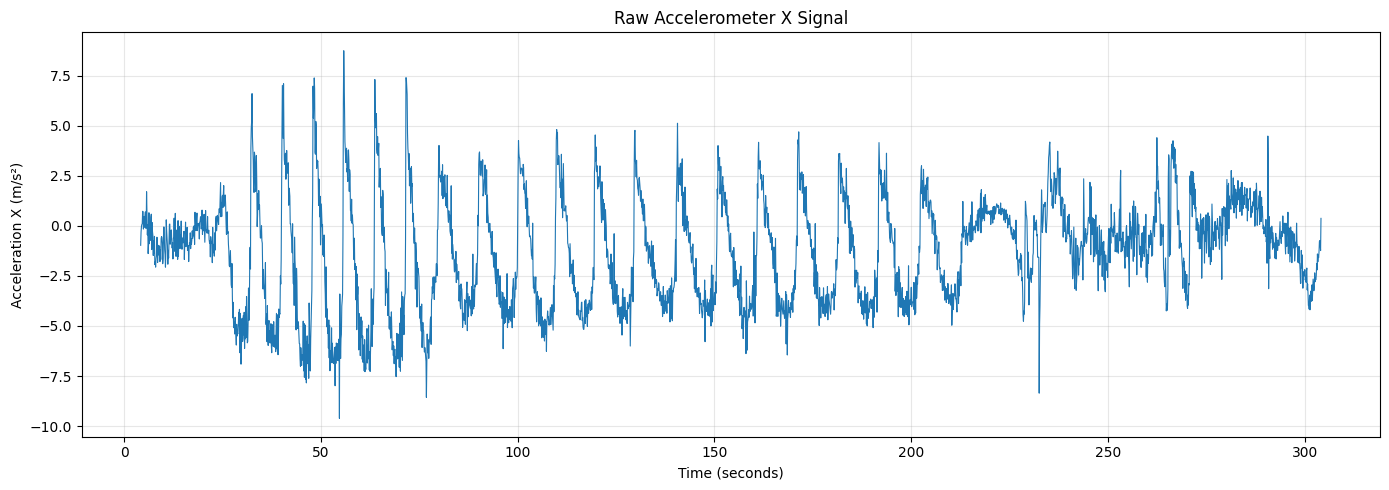

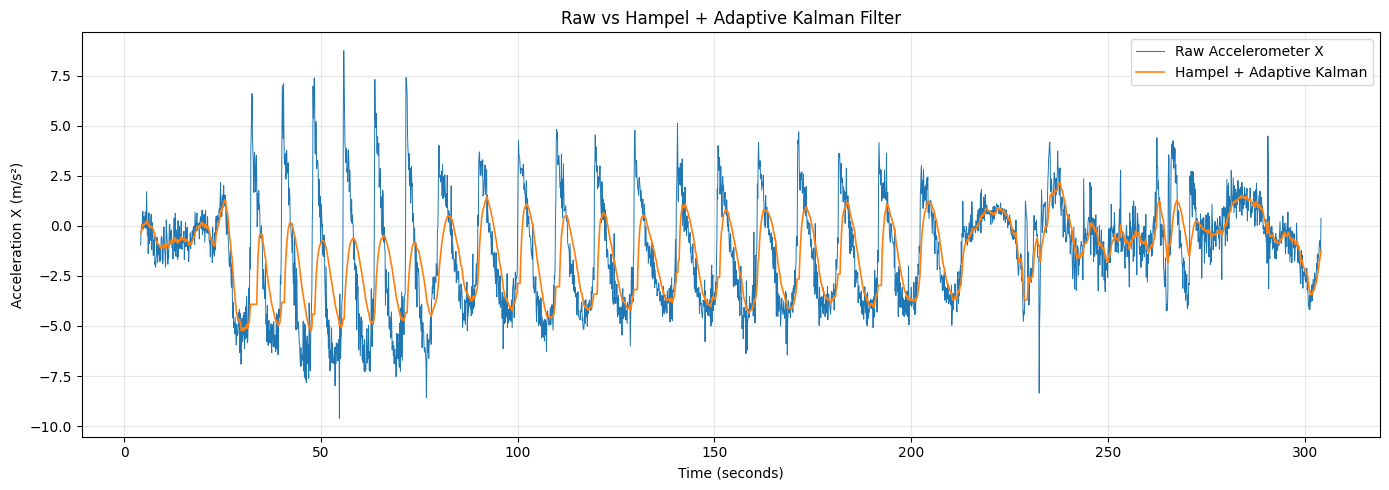


        FILTER PERFORMANCE RESULTS

--- MAE ---
Raw MAE       : 0.457251 m/s²
Filtered MAE  : 0.417507 m/s²
MAE Reduction : 8.69%

--- RMSE ---
Raw RMSE       : 0.758886 m/s²
Filtered RMSE  : 0.682983 m/s²
RMSE Reduction : 10.00%

       NOISE REDUCTION ACCURACY
MAE-based Noise Reduction : 8.69%
RMSE-based Noise Reduction: 10.00%

       ERROR REMAINING
MAE Error Remaining : 91.31%
RMSE Error Remaining: 90.00%



In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD DATA
# ============================================================

file_path = "S-M.csv"

df = pd.read_csv(file_path)

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

# ------------------------------------------------------------
# Select Accelerometer X and GPS Speed
# ------------------------------------------------------------

accel_x_raw = df["ACCELEROMETER X (m/s)"].astype(float).values
gps_speed = df["GPS SPEED (Kmh)"].astype(float).values

# ============================================================
# 2. HAMPel FILTER
# ============================================================

def hampel_filter(signal, window_size=31, n_sigmas=8):

    filtered = signal.copy()
    k = window_size // 2

    for i in range(k, len(signal) - k):

        window = signal[i-k:i+k+1]

        median = np.median(window)

        mad = np.median(np.abs(window - median))

        # Convert MAD to standard deviation estimate
        sigma = 1.4826 * mad

        if sigma == 0:
            continue

        if abs(signal[i] - median) > n_sigmas * sigma:
            filtered[i] = median

    return filtered


# Apply Hampel
accel_x_hampel = hampel_filter(
    accel_x_raw,
    window_size=31,
    n_sigmas=8
)

# ============================================================
# 3. ADAPTIVE KALMAN FILTER
# ============================================================

class AdaptiveKalmanGated:

    def __init__(
        self,
        Q=0.01,
        R=2.0,
        window=30,
        alpha=0.97,
        gate=5
    ):

        self.Q = Q
        self.R = R
        self.window = window
        self.alpha = alpha
        self.gate = gate

        self.x = 0.0
        self.P = 1.0

        self.residuals = []

    def update(self, measurement):

        # Prediction
        x_pred = self.x
        P_pred = self.P + self.Q

        # Innovation
        innovation = measurement - x_pred

        # Innovation variance
        S = P_pred + self.R

        # Gating
        if abs(innovation) > self.gate * np.sqrt(S):

            # Reject extreme measurement
            self.x = x_pred
            self.P = P_pred

            return self.x

        # Kalman gain
        K = P_pred / S

        # Update
        self.x = x_pred + K * innovation
        self.P = (1 - K) * P_pred

        # Store residual
        self.residuals.append(innovation)

        # Adaptive R
        if len(self.residuals) > self.window:

            recent = np.array(
                self.residuals[-self.window:]
            )

            estimated_R = np.var(recent)

            self.R = (
                self.alpha * self.R
                + (1 - self.alpha) * max(estimated_R, 1e-6)
            )

        return self.x


# ============================================================
# 4. APPLY ADAPTIVE KALMAN
# ============================================================

kalman = AdaptiveKalmanGated(
    Q=0.01,
    R=2.0,
    window=30,
    alpha=0.97,
    gate=5
)

accel_x_filtered = np.array([
    kalman.update(x)
    for x in accel_x_hampel
])

# ============================================================
# 5. RAW DATA GRAPH
# ============================================================

# Plot only first 3000 samples for readability
N = min(3000, len(df))

time = df["TIME SINCE START (ms)"].values[:N] / 1000

plt.figure(figsize=(14, 5))

plt.plot(
    time,
    accel_x_raw[:N],
    linewidth=0.8
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration X (m/s²)")
plt.title("Raw Accelerometer X Signal")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


# ============================================================
# 6. FILTERED DATA GRAPH
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    time,
    accel_x_raw[:N],
    linewidth=0.7,
    label="Raw Accelerometer X"
)

plt.plot(
    time,
    accel_x_filtered[:N],
    linewidth=1.2,
    label="Hampel + Adaptive Kalman"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration X (m/s²)")
plt.title("Raw vs Hampel + Adaptive Kalman Filter")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 7. FIND STATIONARY PERIODS
# ============================================================

# Vehicle considered stationary when GPS speed < 0.5 km/h
stationary_mask = gps_speed < 0.5

raw_stationary = accel_x_raw[stationary_mask]
filtered_stationary = accel_x_filtered[stationary_mask]

# Remove NaN / infinite values
raw_stationary = raw_stationary[
    np.isfinite(raw_stationary)
]

filtered_stationary = filtered_stationary[
    np.isfinite(filtered_stationary)
]

# ============================================================
# 8. TRUE ACCELERATION DURING STATIONARY CONDITION
# ============================================================

# During stationary periods:
# True dynamic acceleration ≈ 0

true_value = 0.0

raw_error = raw_stationary - true_value
filtered_error = filtered_stationary - true_value


# ============================================================
# 9. MAE
# ============================================================

raw_mae = np.mean(np.abs(raw_error))

filtered_mae = np.mean(
    np.abs(filtered_error)
)


# ============================================================
# 10. RMSE
# ============================================================

raw_rmse = np.sqrt(
    np.mean(raw_error ** 2)
)

filtered_rmse = np.sqrt(
    np.mean(filtered_error ** 2)
)


# ============================================================
# 11. NOISE REDUCTION %
# ============================================================

mae_reduction = (
    (raw_mae - filtered_mae)
    / raw_mae
) * 100

rmse_reduction = (
    (raw_rmse - filtered_rmse)
    / raw_rmse
) * 100


# ============================================================
# 12. "NOISE REDUCTION ACCURACY"
# ============================================================

# This is NOT conventional classification accuracy.
# It represents percentage reduction in error.

mae_accuracy = mae_reduction
rmse_accuracy = rmse_reduction


# ============================================================
# 13. ERROR REMAINING
# ============================================================

mae_remaining = (
    filtered_mae / raw_mae
) * 100

rmse_remaining = (
    filtered_rmse / raw_rmse
) * 100


# ============================================================
# 14. RESULTS
# ============================================================

print("\n==============================================")
print("        FILTER PERFORMANCE RESULTS")
print("==============================================")

print("\n--- MAE ---")

print(
    f"Raw MAE       : {raw_mae:.6f} m/s²"
)

print(
    f"Filtered MAE  : {filtered_mae:.6f} m/s²"
)

print(
    f"MAE Reduction : {mae_reduction:.2f}%"
)


print("\n--- RMSE ---")

print(
    f"Raw RMSE       : {raw_rmse:.6f} m/s²"
)

print(
    f"Filtered RMSE  : {filtered_rmse:.6f} m/s²"
)

print(
    f"RMSE Reduction : {rmse_reduction:.2f}%"
)


print("\n==============================================")
print("       NOISE REDUCTION ACCURACY")
print("==============================================")

print(
    f"MAE-based Noise Reduction : "
    f"{mae_accuracy:.2f}%"
)

print(
    f"RMSE-based Noise Reduction: "
    f"{rmse_accuracy:.2f}%"
)


print("\n==============================================")
print("       ERROR REMAINING")
print("==============================================")

print(
    f"MAE Error Remaining : "
    f"{mae_remaining:.2f}%"
)

print(
    f"RMSE Error Remaining: "
    f"{rmse_remaining:.2f}%"
)

print("\n==============================================")